# Customer Analytics & Retention Analysis

## Business Objective

Analyze customer behavior, identify high-value customer segments, evaluate retention patterns, and provide recommendations to improve customer lifetime value and customer retention.

## Key Questions

1. How do we understand customer value?
2. Which customers stay or churn?
3. What factors influence retention?
4. Which channels and campaigns drive growth?
5. What actions can improve customer performance?

# Module 1: Data Understanding & Preparation

This module introduces the dataset, evaluates data quality, and prepares the data for customer analytics.

## 1.1 Dataset Overview

Review the structure and key variables of the five datasets used in this project.

In [411]:
# Import libraries for data manipulation and visualization
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display

import matplotlib.ticker as mticker

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression

sns.set_theme(
    style = "whitegrid",
    context = "notebook",
    palette = "deep"
)

# Load datasets
# Customers: customer demographics and acquisition information
# Transactions: purchase history, revenue, discounts, and refunds
# Events: customer engagement and browsing behavior
# Products: product attributes and pricing information
# Campaigns: marketing campaign details and performance metrics

customers = pd.read_csv('/kaggle/input/datasets/geethasagarbonthu/marketing-and-e-commerce-analytics-dataset/customers.csv')
transactions = pd.read_csv('/kaggle/input/datasets/geethasagarbonthu/marketing-and-e-commerce-analytics-dataset/transactions.csv')
events = pd.read_csv('/kaggle/input/datasets/geethasagarbonthu/marketing-and-e-commerce-analytics-dataset/events.csv')
products = pd.read_csv('/kaggle/input/datasets/geethasagarbonthu/marketing-and-e-commerce-analytics-dataset/products.csv')
campaigns = pd.read_csv('/kaggle/input/datasets/geethasagarbonthu/marketing-and-e-commerce-analytics-dataset/campaigns.csv')

In [412]:
# Create a summary table showing the size of each dataset

dataset_summary = pd.DataFrame({
    "Dataset": ["customers", "transactions", "events", "products", "campaigns"],
    "Rows": [
        customers.shape[0],
        transactions.shape[0],
        events.shape[0],
        products.shape[0],
        campaigns.shape[0]
    ],
    "columns": [
        customers.shape[1],
        transactions.shape[1],
        events.shape[1],
        products.shape[1],
        campaigns.shape[1]
    ]
})

dataset_summary

,Dataset,Rows,columns
0,customers,100000,7
1,transactions,103127,9
2,events,2000000,12
3,products,2000,6
4,campaigns,50,7


## 1.2 Data Quality Assessment

Assess data quality by examining missing values, duplicate records, and data consistency.

In [413]:
# Define a function to summarize dataset quality
def show_table_info(df, name):
    print(f"\n==================== {name}: Dataset Structure ====================")

     # Display column names and data types
    display(pd.DataFrame({
        "Column": df.columns,
        "Data Type": df.dtypes.astype(str).tolist()
    }))

    print(f"\n==================== {name}: Preview Data ====================")
    
     # Display sample records
    display(df.head())

    print(f"\n==================== {name}: Missing Values ====================")
    
    # Calculate missing value counts and percentages
    missing = pd.DataFrame({
        "Missing Count": df.isnull().sum(),
        "Missing %": round(df.isnull().mean()*100, 2)
    })
    display(missing)

    print(f"\n==================== {name}: Numerical Summary ====================")
    
   # Generate summary statistics for all numerical features
    num_summary = df.select_dtypes(include = 'number')

    if not num_summary.empty:
        display(num_summary.describe())
    else:
        print("No numerical variables in this dataset")

    print(f"\n==================== {name}: Categorical Summary ====================")
    
     # Generate summary statistics for categorical features
    cat_summary = df.select_dtypes(include = 'object')
    if not cat_summary.empty:
        display(cat_summary.describe())
    else:
        print("No categorical variables in this dataset")

    print(f"\n==================== {name}: Duplicated data checking ====================")
    
    # Check for duplicate records
    print(f"Duplicate rows: {df.duplicated().sum()}")

# Apply inspection function to all datasets
datasets = {
        "Customers": customers,
        "Transactions": transactions,
        "Events": events,
        "Products": products,
        "Campaigns": campaigns
    }

for name, df in datasets.items():
        show_table_info(df, name)    


==================== Customers: Dataset Structure ====================


,Column,Data Type
0,customer_id,int64
1,signup_date,object
2,country,object
3,age,int64
4,gender,object
5,loyalty_tier,object
6,acquisition_channel,object



==================== Customers: Preview Data ====================


,customer_id,signup_date,country,age,gender,loyalty_tier,acquisition_channel
0,1,2021-04-08,BR,48,Male,Bronze,Referral
1,2,2023-04-28,IN,36,Female,Silver,Organic
2,3,2022-12-18,UK,35,Female,Silver,Organic
3,4,2022-04-26,US,45,Male,Silver,Paid Search
4,5,2022-04-20,IN,53,Male,Silver,Organic



==================== Customers: Missing Values ====================


,Missing Count,Missing %
customer_id,0,0.0
signup_date,0,0.0
country,0,0.0
age,0,0.0
gender,0,0.0
loyalty_tier,0,0.0
acquisition_channel,0,0.0


... (41 outputs left out)

,campaign_id,expected_uplift
count,50.00000,50.000000
mean,25.50000,0.086660
std,14.57738,0.035854
min,1.00000,0.022000
25%,13.25000,0.057250
50%,25.50000,0.092500
75%,37.75000,0.113750
max,50.00000,0.144000



==================== Campaigns: Categorical Summary ====================


,channel,objective,start_date,end_date,target_segment
count,50,50,50,50,50
unique,5,4,49,48,5
top,Paid Search,Reactivation,2022-07-25,2022-09-29,New Customers
freq,11,15,2,2,12



==================== Campaigns: Duplicated data checking ====================
Duplicate rows: 0


## 1.3 Data Cleaning & Feature Engineering

Prepare the datasets by validating business rules, inspecting potential data issues, and standardizing data formats.

### Data Cleaning
Transactions with missing product_id or gross_revenue were removed because they cannot contribute to revenue, product, or customer value analysis. Customers associated only with these invalid transactions were retained in the customer dataset and treated as non-buyers in subsequent analyses.

In [414]:
# Keep a copy of the original transaction data
transactions_raw = transactions.copy()

# Check missing values in product_id and gross_revenue
missing_product = transactions['product_id'].isna()
missing_revenue = transactions['gross_revenue'].isna()

print("Missing product_id:", missing_product.sum())
print("Missing gross_revenue:", missing_revenue.sum())

print("Both missing:", (missing_product & missing_revenue).sum())
print("Only product_id missing:", (missing_product & ~missing_revenue).sum())
print("Only gross_revenue missing:", (~missing_product & missing_revenue).sum())

# Check whether the missing records are exactly the same
same_missing_records = missing_product.equals(missing_revenue)
print("Are the missing records exactly the same?", same_missing_records)

# Remove records with missing product_id and gross_revenue.
# These two fields are missing together in 10.13% of the transactions,
# and their values cannot be reliably inferred.
transactions = transactions.dropna(
    subset=['product_id', 'gross_revenue']
).copy()

print(f"Original transactions: {len(transactions_raw):,}")
print(f"Cleaned transactions: {len(transactions):,}")

Missing product_id: 10449
Missing gross_revenue: 10449
Both missing: 10449
Only product_id missing: 0
Only gross_revenue missing: 0
Are the missing records exactly the same? True
Original transactions: 103,127
Cleaned transactions: 92,678


In [415]:
# Fill missing device types with 'Unknown'
events['device_type'] = events['device_type'].fillna('Unknown')

In [416]:
# Convert date column
customers['signup_date'] = pd.to_datetime(customers['signup_date'])
transactions['timestamp'] = pd.to_datetime(transactions['timestamp'])
events['timestamp'] = pd.to_datetime(events['timestamp'])
products['launch_date'] = pd.to_datetime(products['launch_date'])
campaigns['start_date'] = pd.to_datetime(campaigns['start_date'])
campaigns['end_date'] = pd.to_datetime(campaigns['end_date'])

# Replace place holder campaign IDs with missing values
transactions['campaign_id'] = transactions['campaign_id'].replace(0, np.nan)
events['campaign_id'] = events['campaign_id'].replace(0, np.nan)

# Convert ID columns to nullable integers
transactions['product_id'] = transactions['product_id'].astype('int64')
events['product_id'] = events['product_id'].astype('Int64')
transactions['campaign_id'] = transactions['campaign_id'].astype('Int64')
events['campaign_id'] = events['campaign_id'].astype('Int64')

# Standardize traffic source names
events['traffic_source'] = (
    events['traffic_source']
    .str.strip()
    .str.title()
)

In [417]:
# Validate data after preprocessing

print("Customers Data Types")
display(customers.dtypes)

print("\nTransactions Data Types")
display(transactions.dtypes)

print("\nEvents Data Types")
display(events.dtypes)

print("\nProducts Data Types")
display(products.dtypes)

print("\nCampaigns Data Types")
display(campaigns.dtypes)

Customers Data Types


customer_id                     int64
signup_date            datetime64[ns]
country                        object
age                             int64
gender                         object
loyalty_tier                   object
acquisition_channel            object
dtype: object


Transactions Data Types


transaction_id               int64
timestamp           datetime64[ns]
customer_id                  int64
product_id                   int64
quantity                     int64
discount_applied           float64
gross_revenue              float64
campaign_id                  Int64
refund_flag                  int64
dtype: object


Events Data Types


event_id                         int64
timestamp               datetime64[ns]
customer_id                      int64
session_id                       int64
event_type                      object
product_id                       Int64
device_type                     object
traffic_source                  object
campaign_id                      Int64
page_category                   object
session_duration_sec           float64
experiment_group                object
dtype: object


Products Data Types


product_id              int64
category               object
brand                  object
base_price            float64
launch_date    datetime64[ns]
is_premium              int64
dtype: object


Campaigns Data Types


campaign_id                 int64
channel                    object
objective                  object
start_date         datetime64[ns]
end_date           datetime64[ns]
target_segment             object
expected_uplift           float64
dtype: object

### Refund and Revenue Consistency Check

In [418]:
# Compare revenue distribution between refunded and non-refunded transactions

display(
    transactions.groupby('refund_flag')['gross_revenue'].describe()
)

# Calculate refund rate
refund_rate = transactions['refund_flag'].mean()
print(f"Refund Rate: {refund_rate:.2%}")

# Count refund transactions
refund_transactions = transactions[
    transactions['refund_flag'] == 1
]
print(f"Number of refund transactions: {refund_transactions.shape[0]}")

# Validate whether negative revenue transactions are caused by refunds
negative_revenue = transactions[
    transactions['gross_revenue'] < 0
]
result = (
    negative_revenue
    .groupby('refund_flag')
    .size()
    .reset_index(name = 'Number of Transactions')
)

result['refund_flag'] = result['refund_flag'].map({
    0: 'Non-refunded',
    1: 'Refunded'
})
display(result)

# Check revenue impact of refunds
result = (
    transactions
    .groupby('refund_flag')['gross_revenue']
    .agg(
        Transaction_Count = 'count',
        Average_Revenue = 'mean',
        Total_Revenue = 'sum'
    )
    .reset_index()
)
result['refund_flag'] = result['refund_flag'].map({
    0: 'Non-refunded',
    1: 'Refunded'
})
display(result)

,count,mean,std,min,25%,50%,75%,max
refund_flag,,,,,,,,
0,89974.0,95.919591,95.598075,4.09,37.15,70.200,119.70,1858.32
1,2704.0,-94.786594,89.743442,-783.04,-118.35,-71.875,-38.24,-4.48


Refund Rate: 2.92%
Number of refund transactions: 2704


,refund_flag,Number of Transactions
0,Refunded,2704


,refund_flag,Transaction_Count,Average_Revenue,Total_Revenue
0,Non-refunded,89974,95.919591,8630269.31
1,Refunded,2704,-94.786594,-256302.95


### Revenue Distribution Inspection

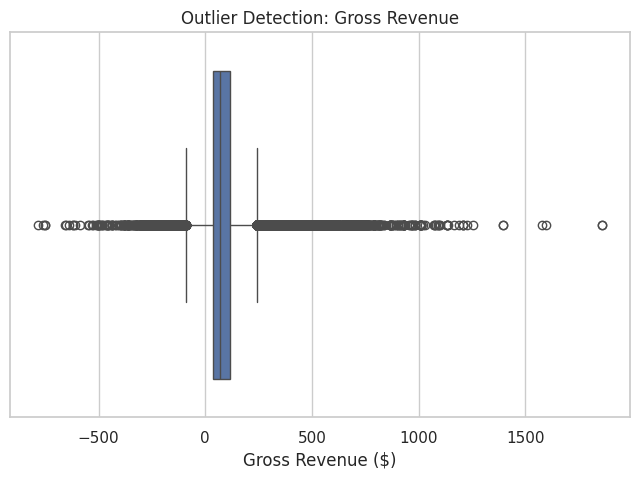

In [419]:
# Visualize gross revenue distribution and identify potential outliers

plt.figure(figsize = (8,5))

sns.boxplot(
    data = transactions,
    x = 'gross_revenue'
)

plt.title("Outlier Detection: Gross Revenue")
plt.xlabel("Gross Revenue ($)")

plt.show()

In [420]:
# Review transactions with the highest revenue values

transactions.nlargest(10, 'gross_revenue')[
    ['transaction_id',
     'customer_id',
     'quantity',
     'gross_revenue',
     'discount_applied',
     'refund_flag'
    ]
]

,transaction_id,customer_id,quantity,gross_revenue,discount_applied,refund_flag
63771,63772,72115,4,1858.32,0.00,0
89725,89726,11800,4,1858.32,0.00,0
39714,39715,67585,4,1597.44,0.00,0
8709,8710,93869,4,1579.57,0.15,0
53552,53553,31613,3,1393.74,0.00,0
57523,57524,54135,3,1393.74,0.00,0
83270,83271,62544,3,1254.37,0.10,0
58001,58002,21602,4,1224.76,0.00,0
15135,15136,34218,4,1207.32,0.00,0
95975,95976,30826,4,1207.32,0.00,0


In [421]:
# Detect revenue outliers using the IQR method

Q1 = transactions['gross_revenue'].quantile(0.25)
Q3 = transactions['gross_revenue'].quantile(0.75)
IQR = Q3 - Q1

upper = Q3 + 1.5 * IQR
lower = Q1 - 1.5 * IQR

outliers = transactions[
    (transactions['gross_revenue'] > upper) | 
    (transactions['gross_revenue'] < lower)
]

print(f"Upper bound: {upper:.2f}")
print(f"Lower bound: {lower:.2f}")
print(f"Number of outliers: {len(outliers)}")
print(f"Outliers percentage: {len(outliers) / len(transactions):.2%}")

Upper bound: 242.68
Lower bound: -90.83
Number of outliers: 6738
Outliers percentage: 7.27%


### Age Inspection

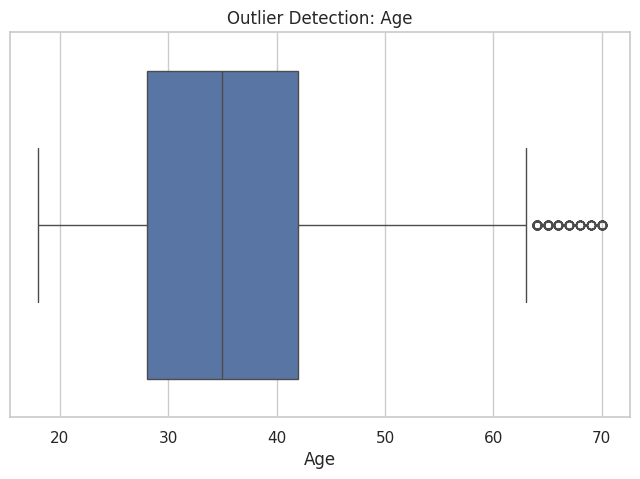

Summary Statistics


count    100000.000000
mean         35.224370
std           9.595792
min          18.000000
25%          28.000000
50%          35.000000
75%          42.000000
max          70.000000
Name: age, dtype: float64


Selected Quantiles


0.01    18.0
0.05    19.0
0.95    51.0
0.99    58.0
Name: age, dtype: float64

In [422]:
# Visualize customer age distribution and inspect summary statistics

plt.figure(figsize = (8,5))

sns.boxplot(
    data = customers,
    x = 'age'
)

plt.title("Outlier Detection: Age")
plt.xlabel("Age")

plt.show()

print("Summary Statistics")
display(customers['age'].describe())

print("\nSelected Quantiles")
display(customers['age'].quantile([0.01, 0.05, 0.95, 0.99]))

In [423]:
# Detect age outliers using the IQR method

Q1 = customers['age'].quantile(0.25)
Q3 = customers['age'].quantile(0.75)
IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

outliers = customers[
    (customers['age'] < lower) | 
    (customers['age'] > upper)
]

print(f"Lower bound: {lower:.1f}")
print(f"Upper bound: {upper:.1f}")
print(f"Number of outliers: {len(outliers)}")
print(f"Percentage: {len(outliers) / len(customers):.2%}")

Lower bound: 7.0
Upper bound: 63.0
Number of outliers: 226
Percentage: 0.23%


### Customer Activity Inspection

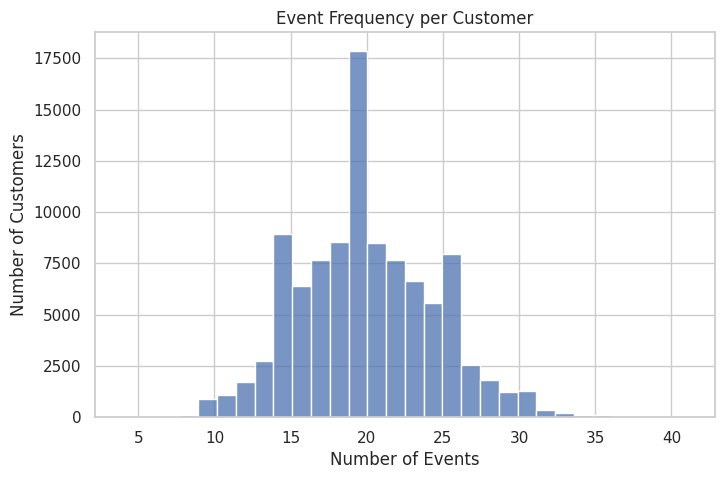

In [424]:
# Calculate the number of events for each customer

event_freq = events.groupby('customer_id').size().reset_index(name = 'event_count')

# Visualize the distribution of customer event frequency
plt.figure(figsize = (8, 5))

sns.histplot(event_freq['event_count'], bins = 30)

plt.title("Event Frequency per Customer")
plt.xlabel("Number of Events")
plt.ylabel("Number of Customers")

plt.show()

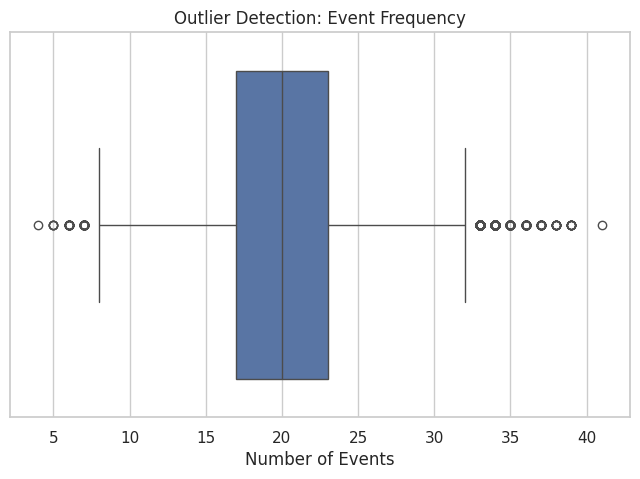

Summary Statistics


count    100000.000000
mean         20.000000
std           4.459639
min           4.000000
25%          17.000000
50%          20.000000
75%          23.000000
max          41.000000
Name: event_count, dtype: float64


Selected Quantiles


0.90    26.0
0.95    28.0
0.99    31.0
Name: event_count, dtype: float64

In [425]:
# Identify potential high-frequency customers

plt.figure(figsize = (8,5))

sns.boxplot(
    data = event_freq,
    x = 'event_count'
)

plt.title("Outlier Detection: Event Frequency")
plt.xlabel("Number of Events")

plt.show()

print("Summary Statistics")
display(event_freq['event_count'].describe())

print("\nSelected Quantiles")
display(
    event_freq['event_count'].quantile([0.90, 0.95, 0.99])
)

In [426]:
# Review customers with the highest event frequency

event_freq.sort_values(
    'event_count',
    ascending = False
).head(10)

,customer_id,event_count
29517,29518,41
40057,40058,39
11609,11610,39
2436,2437,39
36755,36756,39
13513,13514,39
84295,84296,39
7039,7040,39
4150,4151,39
29095,29096,39


## 1.4 Exploratory Data Analysis

Explore customer, transaction, product, and marketing characteristics to understand overall business patterns.

### Loyalty Tier

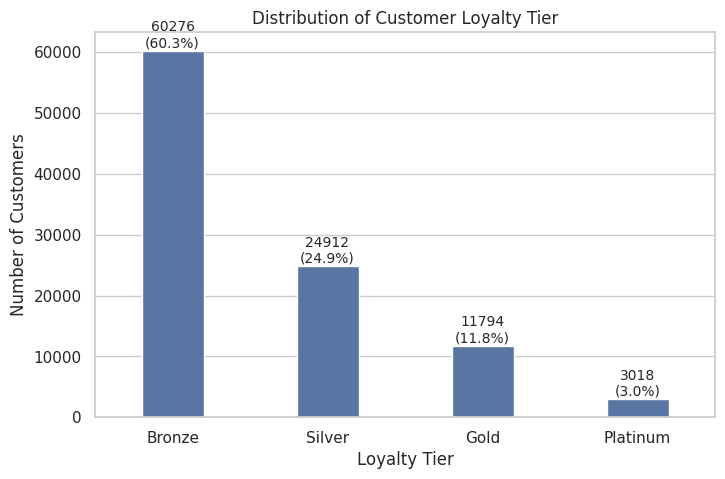

In [427]:
# Visualize customer distribution across loyalty tiers

plt.figure(figsize = (8, 5))

ax = sns.countplot(x = 'loyalty_tier', data = customers, width = 0.4)

total = len(customers)

plt.title("Distribution of Customer Loyalty Tier")
plt.xlabel("Loyalty Tier")
plt.ylabel("Number of Customers")

# Add count and percentage labels above each bar
for p in ax.patches:
    count = int(p.get_height())
    percent = count / total * 100
    ax.annotate(
        f'{count}\n({percent:.1f}%)',
        (p.get_x() + p.get_width() / 2., p.get_height()),
        ha = 'center',
        va = 'bottom',
        fontsize = 10
    )

plt.show()

### Acquisition Channel

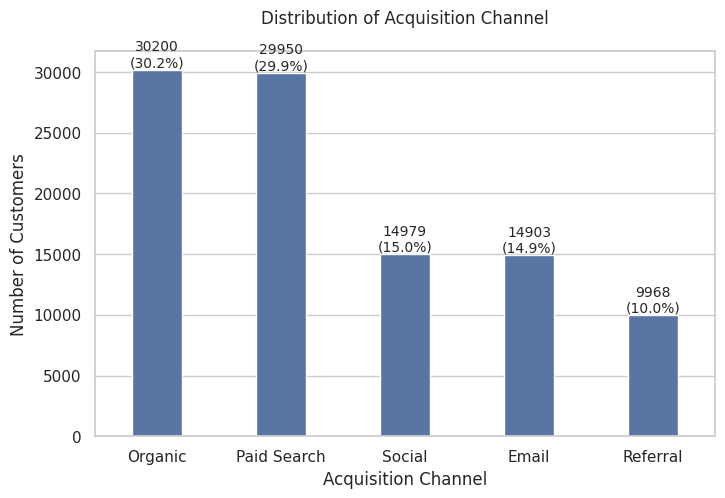

In [428]:
# Visualize customer distribution by acquisition channel

channel_order = customers['acquisition_channel'].value_counts().index

plt.figure(figsize=(8, 5))

ax = sns.countplot(x = 'acquisition_channel', 
                   data = customers, 
                   order = channel_order,
                   width = 0.4)

total = len(customers)

plt.title("Distribution of Acquisition Channel", pad = 20)
plt.xlabel("Acquisition Channel")
plt.ylabel("Number of Customers")

# Add count and percentage labels above each bar
for p in ax.patches:
    count = int(p.get_height())
    percent = count / total * 100
    ax.annotate(
        f'{count}\n({percent:.1f}%)',
        (p.get_x() + p.get_width() / 2., p.get_height()),
        ha = 'center',
        va = 'bottom',
        fontsize = 10
    )

plt.show()

### Age Distribution

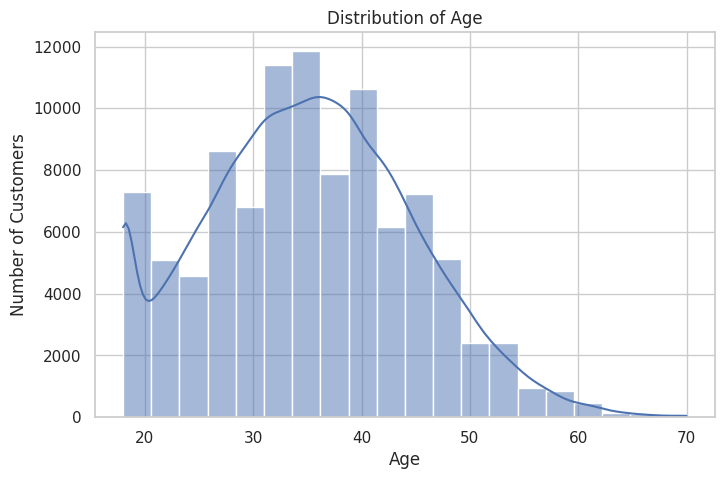

In [429]:
# Visualize the distribution of customer age

plt.figure(figsize = (8, 5))

sns.histplot(customers['age'],
             bins = 20,
             kde = True
            )

plt.title("Distribution of Age")
plt.xlabel("Age")
plt.ylabel("Number of Customers")

plt.show()

### Revenue Distribution

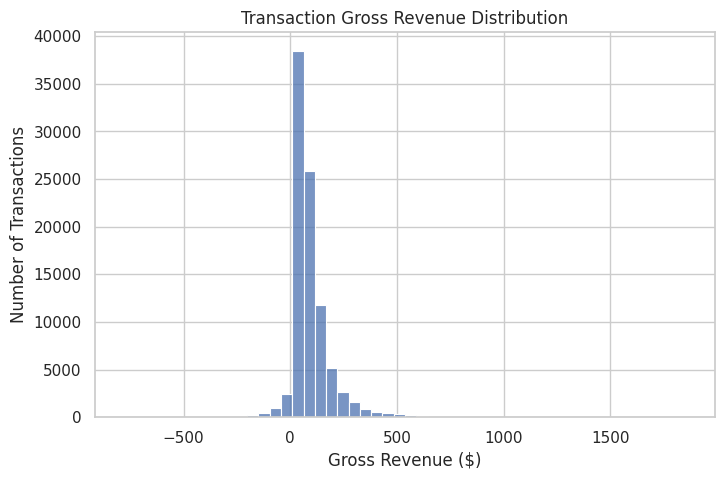

In [430]:
# Plot the distribution of transaction revenue

plt.figure(figsize = (8, 5))

sns.histplot(transactions['gross_revenue'], bins = 50)

plt.title("Transaction Gross Revenue Distribution")
plt.xlabel("Gross Revenue ($)")
plt.ylabel("Number of Transactions")

plt.show()

## Module Summary

### Key findings:

- The five datasets support integrated customer, transaction, product, campaign, and event analysis through their shared identifiers.
- Transactions missing product_id or gross_revenue were excluded from revenue- and product-based analyses; event data provides a separate view of customer behavior.
- Negative transaction revenue is associated with refunds and should be retained when calculating net financial outcomes rather than treated automatically as a data error.
- Revenue and activity distributions are right-skewed, so averages may be influenced by a small number of highly active or high-value records.
- Customer age outliers should be assessed in context rather than removed solely because they fall outside common statistical thresholds.

# Module 2: Customer Value Understanding

This module evaluates customer value using purchasing behavior and customer segmentation.

## Key questions:
- Who are our most valuable customers?
- How do customer groups differ in purchasing behavior?

## 2.1 RFM Customer Segmentation

Segment customers based on Recency, Frequency, and Monetary (RFM) metrics to identify customer value and purchasing behavior.

### RFM Feature Construction

Calculate Recency, Frequency, and Monetary metrics for each customer before customer segmentation.

In [431]:
# Calculate Recency, Frequency, and Monetary metrics for each customer

snapshot_date = transactions['timestamp'].max() + pd.Timedelta(days = 1)

rfm = customers[['customer_id']].merge(
    transactions.groupby('customer_id').agg({
        'timestamp': lambda x: (snapshot_date - x.max()).days,
        'transaction_id': 'count',
        'gross_revenue': 'sum'
    }),
    on='customer_id',
    how='left'
)

rfm.columns = [
    'customer_id',
    'recency',
    'frequency',
    'monetary'
]

In [432]:
# Handle customers with no purchase history

max_recency = rfm['recency'].max()
    
rfm['recency'] = rfm['recency'].fillna(max_recency + 1)
rfm['frequency'] = rfm['frequency'].fillna(0)
rfm['monetary'] = rfm['monetary'].fillna(0)

In [433]:
# Calculate RFM scores using quintile-based segmentation

# Identify customers with valid purchase history
buyer_mask = rfm['frequency'] > 0

# Initialize RFM scores
rfm['r_score'] = 1
rfm['f_score'] = 1
rfm['m_score'] = 1

# Assign R scores to buyers based on recency quintiles
# Lower recency is better: 5 = most recent, 1 = least recent
rfm.loc[buyer_mask, 'r_score'] = pd.qcut(
    rfm.loc[buyer_mask, 'recency'].rank(method = 'first'),
    5,
    labels = [5, 4, 3, 2, 1]
).astype(int)

# Assign F scores to buyers based on purchase frequency quintiles
# Higher frequency is better: 5 = highest frequency
rfm.loc[buyer_mask, 'f_score'] = pd.qcut(
    rfm.loc[buyer_mask, 'frequency'].rank(method = 'first'),
    5,
    labels=[1, 2, 3, 4, 5]
).astype(int)

# Assign M scores to buyers based on monetary value quintiles
# Higher monetary value is better: 5 = highest value
rfm.loc[buyer_mask, 'm_score'] = pd.qcut(
    rfm.loc[buyer_mask, 'monetary'].rank(method = 'first'),
    5,
    labels=[1, 2, 3, 4, 5]
).astype(int)

# Ensure score columns are integers
rfm['r_score'] = rfm['r_score'].astype(int)
rfm['f_score'] = rfm['f_score'].astype(int)
rfm['m_score'] = rfm['m_score'].astype(int)

In [434]:
# Create refund-related features for each customer

transactions['is_refund'] = transactions['gross_revenue'] < 0

refund_features = transactions.groupby('customer_id').agg(
    refund_count = ('is_refund', 'sum'),
    total_orders = ('transaction_id', 'count'),
    refund_amount = ('gross_revenue', lambda x: x[x < 0].sum())
).reset_index()

refund_features['refund_rate'] = (
    refund_features['refund_count']
    / refund_features['total_orders']
)

rfm = rfm.merge(
    refund_features,
    on = 'customer_id',
    how = 'left'
)

rfm['refund_rate'] = rfm['refund_rate'].fillna(0)

### RFM Feature Exploration

Before segmenting customers, we examine the distributions of recency, frequency, and monetary value to better understand customer purchasing behavior.

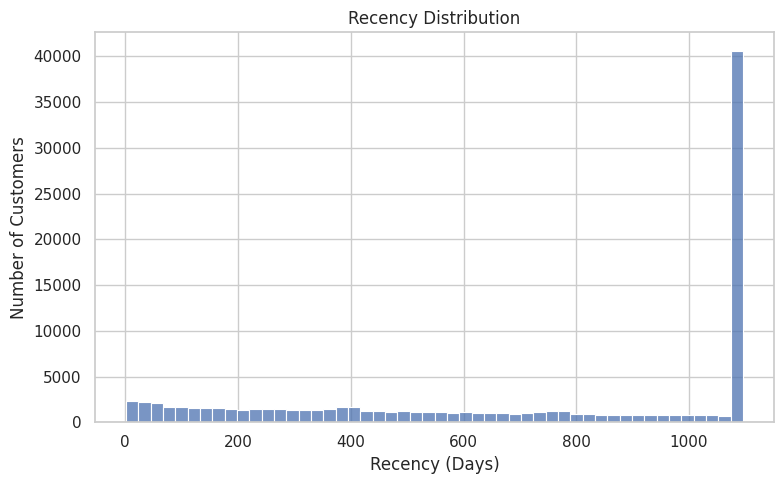

In [435]:
# Visualize the distribution of customer recency

plt.figure(figsize = (8, 5))

sns.histplot(
    rfm['recency'],
    bins = 50
)

plt.title('Recency Distribution')
plt.xlabel('Recency (Days)')
plt.ylabel('Number of Customers')

plt.tight_layout()
plt.show()

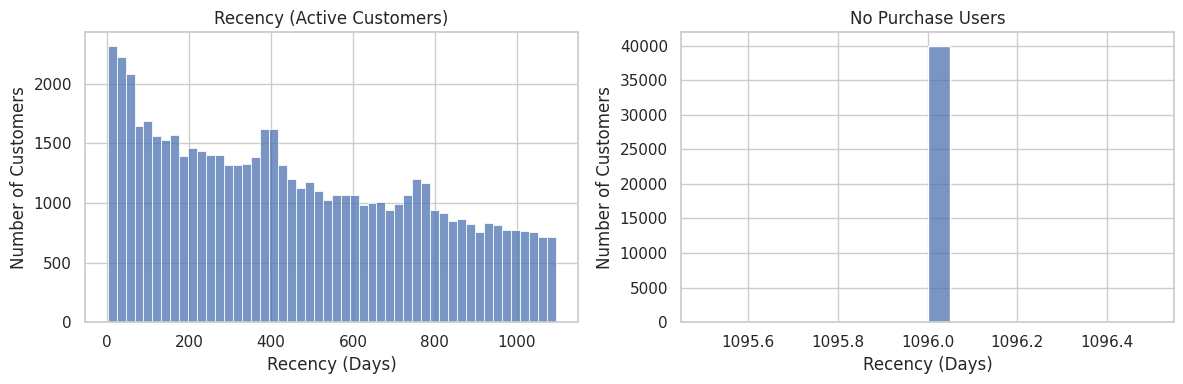

In [436]:
# Compare recency between active customers and non-buyers

rfm['recency'] = rfm['recency'].astype(int)

no_purchase = rfm['frequency'] == 0

fig, axes = plt.subplots(1, 2, figsize = (12, 4))

# Recency distribution for active customers
sns.histplot(
    rfm.loc[~no_purchase, 'recency'],
    bins = 50,
    ax = axes[0]
)
axes[0].set_title('Recency (Active Customers)')
axes[0].set_xlabel('Recency (Days)')
axes[0].set_ylabel('Number of Customers')

# Recency distribution for customers without purchase history
sns.histplot(
    rfm.loc[no_purchase, 'recency'],
    bins = 20,
    ax = axes[1]
)
axes[1].set_title('No Purchase Users')
axes[1].set_xlabel('Recency (Days)')
axes[1].set_ylabel('Number of Customers')

plt.tight_layout()
plt.show()

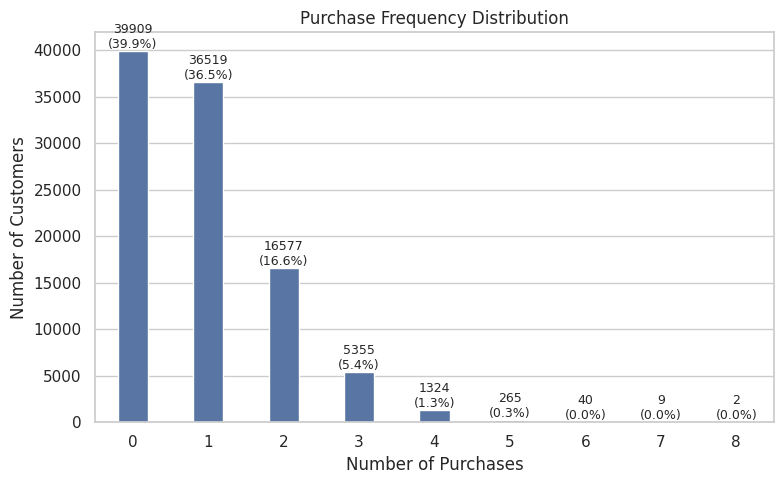

In [437]:
# Visualize customer purchase frequency

rfm['frequency'] = rfm['frequency'].astype(int)

plt.figure(figsize = (8, 5))

ax = sns.countplot(
    data = rfm,
    x = 'frequency',    
    width = 0.4
)

total = len(rfm)

plt.title("Purchase Frequency Distribution")
plt.xlabel("Number of Purchases")
plt.ylabel("Number of Customers")

for p in ax.patches:
    count = int(p.get_height())
    percent = count / total * 100
    ax.annotate(
        f'{count}\n({percent:.1f}%)',
        (p.get_x() + p.get_width() / 2, p.get_height()),
        ha = 'center',
        va = 'bottom',
        fontsize = 9
    )

plt.tight_layout()
plt.show()

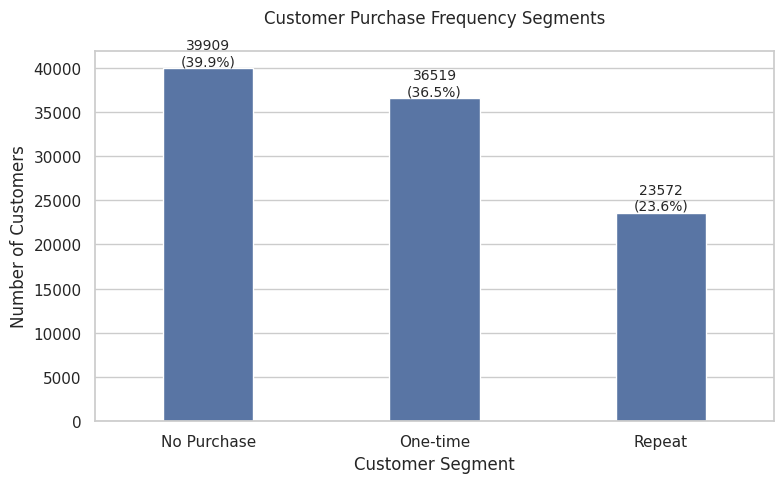

In [438]:
# Categorize customers by purchase frequency

rfm['segment'] = rfm['frequency'].apply(
    lambda x: 'No Purchase' if x == 0 else
              'One-time' if x == 1 else
              'Repeat'
)

# Visualize customer segments by purchase behavior
plt.figure(figsize = (8, 5))

ax = sns.countplot(
    data = rfm,
    x = 'segment',    
    width = 0.4
)

total = len(rfm)

plt.title("Customer Purchase Frequency Segments", pad = 20)
plt.xlabel("Customer Segment")
plt.ylabel("Number of Customers")

for p in ax.patches:
    count = int(p.get_height())
    percent = count / total * 100
    ax.annotate(
        f'{count}\n({percent:.1f}%)',
        (p.get_x() + p.get_width() / 2, p.get_height()),
        ha = 'center',
        va = 'bottom',
        fontsize = 10
    )

plt.tight_layout()
plt.show()

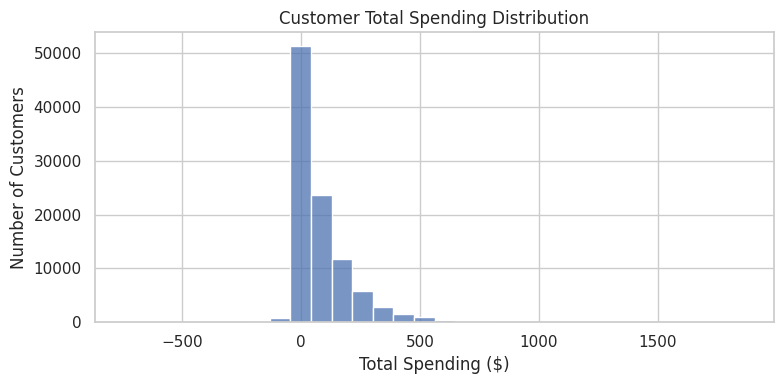

In [439]:
# Visualize customer monetary value

plt.figure(figsize = (8, 4))

sns.histplot(
    rfm['monetary'],
    bins = 30
)

plt.title('Customer Total Spending Distribution')
plt.xlabel('Total Spending ($)')
plt.ylabel('Number of Customers')

plt.tight_layout()
plt.show()

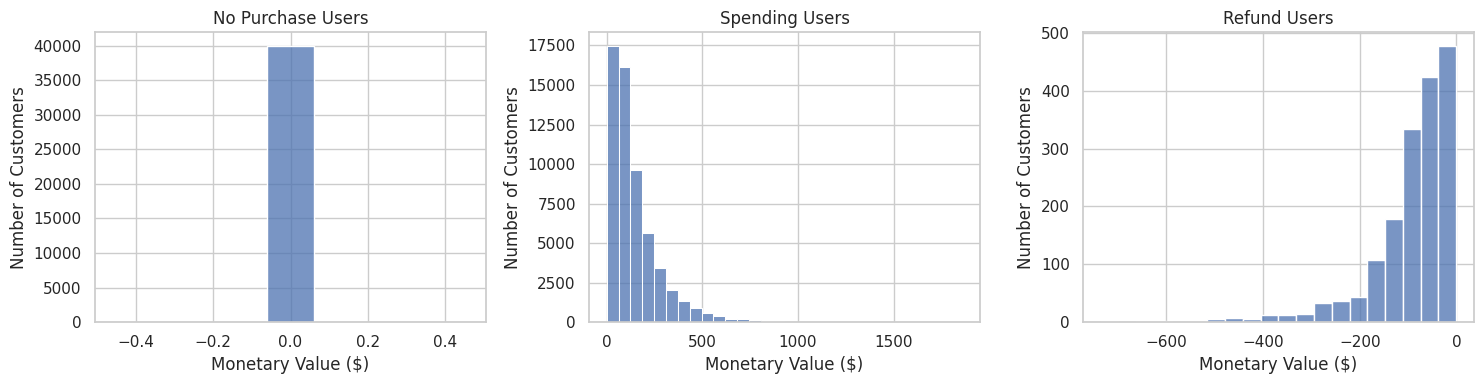

In [440]:
# Compare monetary value across customer groups

fig, axes = plt.subplots(1, 3, figsize=(15,4))

# Customers without purchase history
sns.histplot(
    rfm[rfm['monetary'] == 0]['monetary'],
    bins = 5,
    shrink = 0.6,
    ax = axes[0]
)
axes[0].set_title('No Purchase Users')

# Customers with positive spending
sns.histplot(
    rfm[rfm['monetary'] > 0]['monetary'],
    bins = 30,
    ax = axes[1]
)
axes[1].set_title('Spending Users')

# Customers with net negative spending due to refunds
sns.histplot(
    rfm[rfm['monetary'] < 0]['monetary'],
    bins = 20,
    ax = axes[2]
)
axes[2].set_title('Refund Users')

for ax in axes:
    ax.set_xlabel('Monetary Value ($)')
    ax.set_ylabel('Number of Customers')

plt.tight_layout()
plt.show()

In [441]:
# Categorize customers based on monetary value

rfm['monetary_type'] = np.where(
    rfm['monetary'] < 0,
    'Refund',
    np.where(
        rfm['monetary'] == 0,
        'No Purchase',
        'Positive Spend'
    )
)

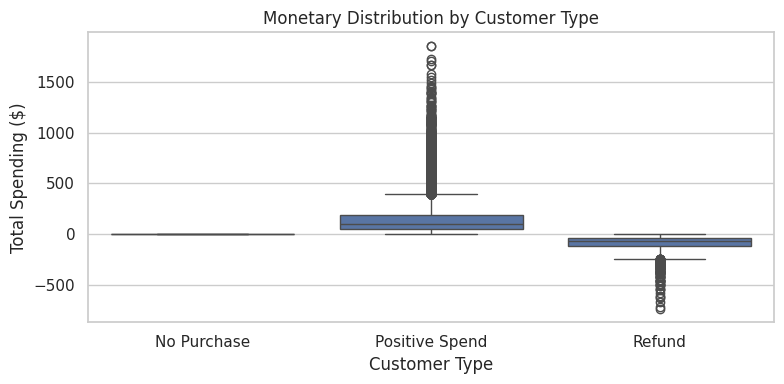

In [442]:
# Compare monetary value by customer type

plt.figure(figsize = (8,4))

sns.boxplot(
    x = 'monetary_type',
    y = 'monetary',
    data = rfm
)

plt.title('Monetary Distribution by Customer Type')
plt.xlabel('Customer Type')
plt.ylabel('Total Spending ($)')

plt.tight_layout()
plt.show()

### RFM Score Validation

Validate the calculated RFM scores before customer segmentation.

In [443]:
# Validate RFM score data types

rfm['r_score'] = rfm['r_score'].astype(int)
rfm['f_score'] = rfm['f_score'].astype(int)
rfm['m_score'] = rfm['m_score'].astype(int)

# Preview customer-level RFM features
rfm[[
        'customer_id',
        'recency',
        'frequency',
        'monetary',
        'r_score',
        'f_score',
        'm_score'
    ]].head()

,customer_id,recency,frequency,monetary,r_score,f_score,m_score
0,1,1096,0,0.00,1,1,1
1,2,1066,1,60.09,1,1,2
2,3,1096,0,0.00,1,1,1
3,4,1096,0,0.00,1,1,1
4,5,1096,0,0.00,1,1,1


In [444]:
# Review the distribution of RFM scores

rfm[['r_score', 'f_score', 'm_score']].describe()

,r_score,f_score,m_score
count,100000.000000,100000.000000,100000.000000
mean,2.201840,2.201800,2.201800
std,1.470089,1.470067,1.470067
min,1.000000,1.000000,1.000000
25%,1.000000,1.000000,1.000000
50%,1.000000,1.000000,1.000000
75%,3.000000,3.000000,3.000000
max,5.000000,5.000000,5.000000


### Customer Segmentation

Customers are segmented using RFM scores together with refund behavior to identify high-value customers, low-engagement users, and potential customer risks.

In [445]:
# Define customer segments

def segment(row):

    # Customers without valid purchase history
    if row['frequency'] == 0:
        return "Never Purchased"

    # Customers with negative net revenue
    if row['monetary'] < 0:
        return "Net Negative Customers"

    # Customers with a high refund rate
    if row['refund_rate'] > 0.3:
        return "High Refund Risk"

    # High-value customers
    if (
        row['r_score'] >= 4
        and row['f_score'] >= 4
        and row['m_score'] >= 4
    ):
        return "Champions"

    # Customers with relatively strong overall value
    if (
        row['r_score'] >= 3
        and row['f_score'] >= 3
        and row['m_score'] >= 3
    ):
        return "Loyal Customers"

    # Recent customers with low purchase frequency
    if (
        row['r_score'] >= 4
        and row['f_score'] <= 2
    ):
        return "New / Potential Loyalists"

    # Buyers who have not purchased recently
    if row['r_score'] <= 2:
        return "Low Engagement Users"

    # Remaining customers
    return "Others"

rfm['segment'] = rfm.apply(
    segment,
    axis = 1
)

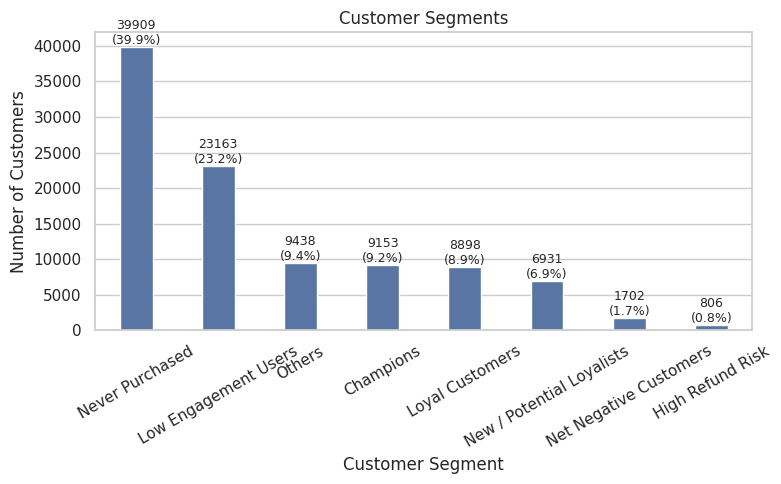

In [446]:
# Visualize customer segment distribution

segment_counts = rfm['segment'].value_counts()

plt.figure(figsize = (8, 5))

ax = sns.countplot(
    data = rfm,
    x = 'segment',
    order = segment_counts.index, 
    width = 0.4
)

for p in ax.patches:
    count = int(p.get_height())
    pct = count / len(rfm) * 100      
    ax.annotate(
        f'{count}\n({pct:.1f}%)',
        (p.get_x() + p.get_width()/2, p.get_height()),
        ha = 'center',
        va = 'bottom',
        fontsize = 9
    )

plt.title('Customer Segments')
plt.xlabel('Customer Segment')
plt.ylabel('Number of Customers')
plt.xticks(rotation = 30)

plt.tight_layout()
plt.show()

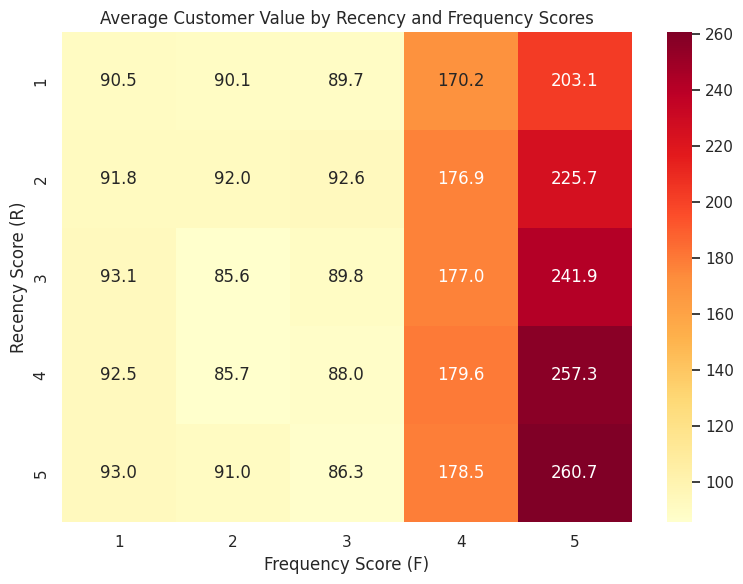

In [447]:
# Compare average customer value across RFM score combinations

# Exclude customers without purchase history
rfm_filtered = rfm[rfm['frequency'] > 0]

# Create R-F score matrix with average monetary value
pivot = rfm_filtered.pivot_table(
    values = 'monetary',
    index = 'r_score',
    columns = 'f_score',
    aggfunc = 'mean'
)

plt.figure(figsize = (8, 6))

sns.heatmap(
    pivot,
    annot = True,
    fmt = '.1f',
    cmap = 'YlOrRd'
)

plt.title('Average Customer Value by Recency and Frequency Scores')
plt.xlabel('Frequency Score (F)')
plt.ylabel('Recency Score (R)')

plt.tight_layout()
plt.show()

In [448]:
# Summarize customer count, behavior, and revenue metrics for each RFM segment

rfm_segment_summary = (
    rfm.groupby('segment')
    .agg(
        customers = ('customer_id', 'nunique'),
        avg_recency = ('recency', 'mean'),
        avg_frequency = ('frequency', 'mean'),
        avg_monetary = ('monetary', 'mean'),
        total_monetary = ('monetary', 'sum'),
        avg_refund_rate = ('refund_rate', 'mean')
    )
    .round(2)
)

rfm_segment_summary['customer_share'] = (
    rfm_segment_summary['customers']
    / rfm_segment_summary['customers'].sum()
)

rfm_segment_summary['revenue_share'] = (
    rfm_segment_summary['total_monetary']
    / rfm_segment_summary['total_monetary'].sum()
)

display(rfm_segment_summary)

,customers,avg_recency,avg_frequency,avg_monetary,total_monetary,avg_refund_rate,customer_share,revenue_share
segment,,,,,,,,
Champions,9153,138.94,2.61,291.86,2671354.13,0.00,0.09153,0.319007
High Refund Risk,806,314.52,2.44,108.79,87686.09,0.43,0.00806,0.010471
Low Engagement Users,23163,789.11,1.25,120.31,2786810.94,0.00,0.23163,0.332795
Loyal Customers,8898,306.57,1.94,187.58,1669077.46,0.00,0.08898,0.199317
Net Negative Customers,1702,464.24,1.45,-92.51,-157450.34,0.81,0.01702,-0.018802
Never Purchased,39909,1096.00,0.00,0.00,0.00,0.00,0.39909,0.000000
New / Potential Loyalists,6931,155.81,1.00,96.00,665373.95,0.00,0.06931,0.079457
Others,9438,328.28,1.19,68.99,651114.13,0.00,0.09438,0.077755


### Key Findings

- Activation opportunity: 39.91% of customers in the churn dataset have never purchased, so first-purchase activation should be treated separately from buyer retention.
- High-value segments: Champions and Loyal Customers show stronger purchasing value and are candidates for loyalty-focused retention.
- Re-engagement opportunity: Low Engagement Users and customers with long purchase recency may need targeted reactivation.
- Refund risk: High Refund Risk and Net Negative Customers should be assessed using net revenue and refund behavior, not purchase frequency alone.

## 2.2 Customer Lifetime Value (CLV)

Customer Lifetime Value (CLV) estimates the long-term revenue contribution of each customer based on historical purchasing behavior.

This analysis evaluates customer value, purchasing patterns, and refund-adjusted lifetime value.

In [449]:
# Calculate customer-level revenue metrics

clv = customers[['customer_id']].merge(
    transactions.groupby('customer_id').agg(
        total_revenue = ('gross_revenue', 'sum'),
        frequency = ('transaction_id', 'count'),
        avg_order_value = ('gross_revenue', 'mean')
    ),
    on = 'customer_id',
    how = 'left'
)

# Handle customers without purchase history
clv['total_revenue'] = clv['total_revenue'].fillna(0)
clv['frequency'] = clv['frequency'].fillna(0).astype(int)
clv['avg_order_value'] = clv['avg_order_value'].fillna(0)

In [450]:
# Compare buyers and non-buyers

clv['is_buyer'] = clv['frequency'] > 0

# Conversion Rate
conversion_rate = clv['is_buyer'].mean()
print(f'Conversion Rate: {conversion_rate:.2%}')

# Average revenue by buyer status
revenue_summary = (
    clv.groupby('is_buyer')['total_revenue']
    .mean()
    .reset_index(name = 'Average Revenue')
    .rename(columns = {'is_buyer': 'Customer Type'})
)
revenue_summary['Customer Type'] = revenue_summary['Customer Type'].map({
    True: 'Buyer',
    False: 'Non-buyer'
})
display(revenue_summary)

# Buyer distribution
buyer_distribution = (
    clv['is_buyer']
    .value_counts(normalize = True)
    .mul(100)
    .round(2)
    .reset_index(name = 'Percentage (%)')
    .rename(columns = {'is_buyer': 'Customer Type'})
)
buyer_distribution['Customer Type'] = buyer_distribution['Customer Type'].map({
    True: 'Buyer',
    False: 'Non-buyer'
})
display(buyer_distribution)

Conversion Rate: 60.09%


,Customer Type,Average Revenue
0,Non-buyer,0.000000
1,Buyer,139.354751


,Customer Type,Percentage (%)
0,Buyer,60.09
1,Non-buyer,39.91


In [451]:
# Calculate customer lifetime value metrics

buyers = transactions.groupby('customer_id').agg(
    total_revenue = ('gross_revenue', 'sum'),
    frequency = ('transaction_id', 'count'),
    first_purchase = ('timestamp', 'min'),
    last_purchase = ('timestamp', 'max')
).reset_index()

buyers['lifespan_days'] = (
    buyers['last_purchase'] -
    buyers['first_purchase']
).dt.days + 1

buyers['aov'] = (
    buyers['total_revenue'] /
    buyers['frequency']
)

In [452]:
# Adjust CLV based on refund behavior

refund = transactions.groupby('customer_id').agg(
    refund_count = ('refund_flag', 'sum'),
    order_count = ('transaction_id', 'count')
).reset_index()

refund['refund_rate'] = refund['refund_count'] / refund['order_count']

buyers = buyers.merge(
    refund[['customer_id','refund_rate']],
    on = 'customer_id',
    how = 'left'
)

buyers['refund_rate'] = buyers['refund_rate'].fillna(0)

# Calculate refund-adjusted customer lifetime value
buyers['adjusted_clv'] = (
    buyers['total_revenue'] *
    (1 - buyers['refund_rate'])
)

### CLV Segmentation

Customers are divided into four value groups based on normalized CLV scores.

In [453]:
# Create CLV segments

buyers['clv_score'] = (
    buyers['adjusted_clv'] - buyers['adjusted_clv'].min()
) / (
    buyers['adjusted_clv'].max() - buyers['adjusted_clv'].min()
)

buyers['clv_segment'] = pd.qcut(
    buyers['clv_score'],
    4,
    labels=['Low','Mid-Low','Mid-High','High']
)

In [454]:
# Summarize customer characteristics by CLV segment

clv_summary = buyers.groupby(
    'clv_segment',
    observed = True
).agg(
    customers = ('customer_id', 'count'),
    avg_clv = ('adjusted_clv', 'mean'),
    total_clv = ('adjusted_clv', 'sum'),
    avg_lifespan = ('lifespan_days', 'mean'),
    avg_refund_rate = ('refund_rate', 'mean')
)

display(clv_summary)

,customers,avg_clv,total_clv,avg_lifespan,avg_refund_rate
clv_segment,,,,,
Low,15024,22.831704,3.430235e+05,48.950280,0.105858
Mid-Low,15025,72.862756,1.094763e+06,88.432346,0.005888
Mid-High,15021,137.623227,2.067238e+06,194.665668,0.003618
High,15021,329.781341,4.953646e+06,344.863125,0.002244


In [455]:
# Compare CLV across RFM segments

rfm_buyers = rfm.merge(buyers, on = 'customer_id', how = 'left')

rfm_buyers.groupby(
    'segment'
)['adjusted_clv'].mean()

pd.crosstab(
    rfm_buyers['segment'],
    rfm_buyers['clv_segment']
)

clv_segment,Low,Mid-Low,Mid-High,High
segment,,,,
Champions,0,3,2622,6528
High Refund Risk,445,193,114,54
Low Engagement Users,6440,6751,5751,4221
Loyal Customers,0,1920,4025,2953
Net Negative Customers,1702,0,0,0
New / Potential Loyalists,2340,2258,1569,764
Others,4097,3900,940,501


### CLV Distribution

Visualize the distribution of customer lifetime value to understand customer value concentration and identify high-value customers.

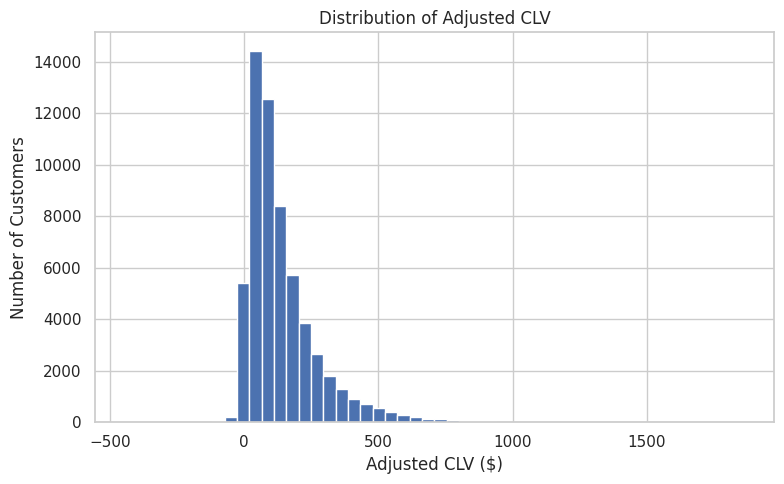

In [456]:
# Visualize the distribution of adjusted CLV

plt.figure(figsize = (8,5))

plt.hist(buyers['adjusted_clv'], bins = 50)

plt.title('Distribution of Adjusted CLV')
plt.xlabel('Adjusted CLV ($)')
plt.ylabel('Number of Customers')

plt.tight_layout()
plt.show()

### CLV Segment Analysis

Analyze revenue contribution across different CLV segments.

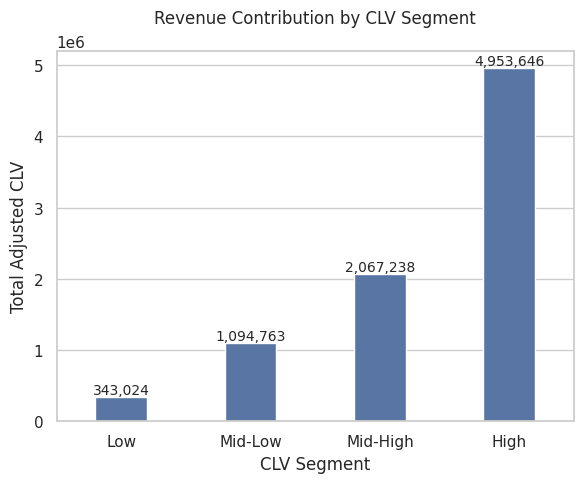

In [457]:
# Compare revenue contribution across CLV segments

plt.figure(figsize = (6, 5))

ax = sns.barplot(
    data = clv_summary,
    x = 'clv_segment',
    y = 'total_clv',
    width = 0.4
)
plt.xticks(rotation = 0)

plt.title('Revenue Contribution by CLV Segment', pad=20)
plt.xlabel('CLV Segment')
plt.ylabel('Total Adjusted CLV')

# Add value labels
for p in ax.patches:
    value = p.get_height()
    ax.annotate(
        f'{value:,.0f}',
        (p.get_x() + p.get_width() / 2, value),
        ha = 'center',
        va = 'bottom',
        fontsize = 10
    )

plt.tight_layout()
plt.show()

### CLV Drivers Analysis

Explore the relationship between customer lifetime value and customer behavior characteristics.

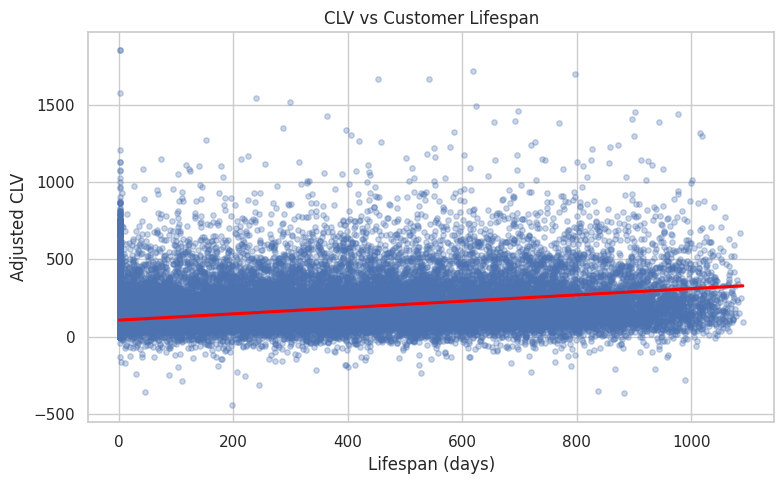

In [458]:
# Explore the relationship between customer lifespan and CLV

plt.figure(figsize = (8,5))

sns.regplot(
    data = buyers,
    x = 'lifespan_days',
    y = 'adjusted_clv',
    scatter_kws = {'alpha': 0.3, 's': 15},
    line_kws = {'color': 'red'}
)

plt.title('CLV vs Customer Lifespan')
plt.xlabel('Lifespan (days)')
plt.ylabel('Adjusted CLV')

plt.tight_layout()
plt.show()

### Refund Impact Analysis

Evaluate how refund behavior affects customer lifetime value.

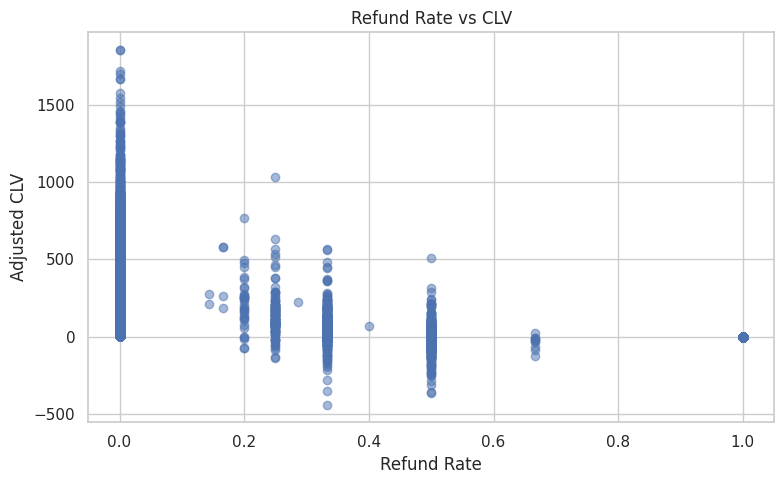

In [459]:
# Explore the relationship between refund rate and CLV

plt.figure(figsize = (8,5))

plt.scatter(buyers['refund_rate'], buyers['adjusted_clv'], alpha = 0.5)

plt.title('Refund Rate vs CLV')
plt.xlabel('Refund Rate')
plt.ylabel('Adjusted CLV')

plt.tight_layout()
plt.show()

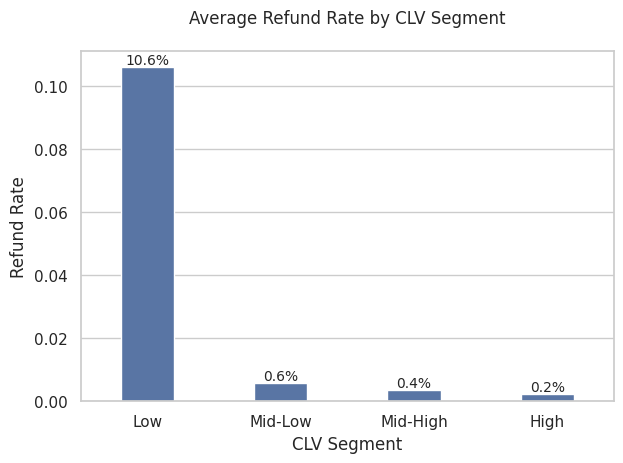

In [460]:
# Compare refund rates across CLV segments

ax = sns.barplot(
    data = clv_summary,
    x = 'clv_segment',
    y = 'avg_refund_rate',
    width = 0.4
)

plt.title('Average Refund Rate by CLV Segment', pad=20)
plt.xlabel('CLV Segment')
plt.ylabel('Refund Rate')

for p in ax.patches:
    value = p.get_height()
    ax.annotate(
        f'{value:.1%}',
        (p.get_x() + p.get_width() / 2, value),
        ha = 'center',
        va = 'bottom',
        fontsize = 10
    )

plt.xticks(rotation = 0)

plt.tight_layout()
plt.show()

### Key Findings

- The High CLV segment has the highest average adjusted CLV (`$329.78`) and contributes approximately `$4.95` million in total adjusted CLV among 15,021 customers.
- Average adjusted CLV rises across the four segments: `$22.83` (Low), `$72.86` (Mid-Low), `$137.62` (Mid-High), and `$329.78` (High).
- The average refund rate is highest in the Low CLV segment (10.6%) and falls to 0.2% in the High CLV segment, indicating that refund behavior is an important dimension of customer value.
- Average observed purchasing lifespan also increases across CLV groups, from about 49 days in Low to 345 days in High. This is an association in the observed data, not proof that longer tenure causes higher value.
- Mid-High and Mid-Low customers may be candidates for repeat-purchase and cross-selling programs, while high-refund customers warrant separate investigation.

## 2.3 Customer Clustering

To identify customers with similar purchasing behavior, we perform customer segmentation using K-Means clustering.

The clustering model is built using four customer-level features: Recency, Frequency, Monetary, Refund Rate. All features are standardized before clustering.

### Feature Preparation

Prepare customer-level features for clustering analysis.

In [461]:
# Build the clustering dataset

cluster_df = rfm.copy()

buyer_cluster = cluster_df[
    cluster_df['frequency'] > 0
].copy()

# Fill missing values for customers without purchase history
buyer_cluster[
    ['recency', 'frequency', 'monetary', 'refund_rate']
] = buyer_cluster[
    ['recency', 'frequency', 'monetary', 'refund_rate']
].fillna(0)

In [462]:
# Standardize clustering features

features = ['recency','frequency','monetary','refund_rate']

cluster_features = buyer_cluster[features].copy()

cluster_features['frequency'] = np.log1p(
    cluster_features['frequency']
)

cluster_features['monetary'] = (
    np.sign(cluster_features['monetary'])
    * np.log1p(np.abs(cluster_features['monetary']))
)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(cluster_features)

### Selecting the Optimal Number of Clusters

The Elbow Method is used to determine an appropriate number of customer clusters.

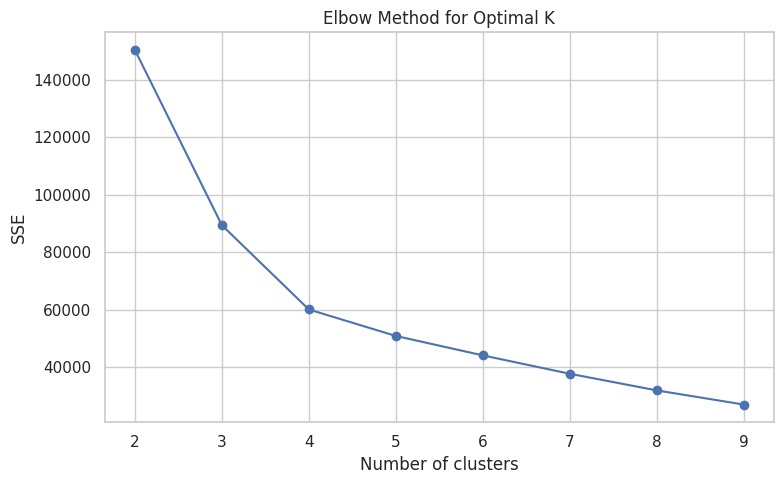

In [463]:
# Determine the optimal number of clusters using the Elbow Method

sse = []

K_range = range(2, 10)

for k in K_range:
    kmeans = KMeans(n_clusters = k, 
                    random_state = 42, 
                    n_init = 10
                   )
    kmeans.fit(X_scaled)
    sse.append(kmeans.inertia_)

plt.figure(figsize = (8, 5))

plt.plot(K_range, sse, marker = 'o')

plt.title('Elbow Method for Optimal K')
plt.xlabel('Number of clusters')
plt.ylabel('SSE')

plt.tight_layout()
plt.show()

### K-Means Clustering

Based on the Elbow Method, K = 4 is selected to segment customers into four behavioral groups.

In [464]:
# Perform customer clustering using K-Means

kmeans = KMeans(n_clusters = 4, random_state = 42, n_init = 10)
buyer_cluster['cluster'] = kmeans.fit_predict(X_scaled)

In [465]:
# Summarize customer characteristics by cluster

cluster_summary = buyer_cluster.groupby('cluster').agg(
    customers = ('customer_id', 'count'),
    recency = ('recency', 'mean'),
    frequency = ('frequency', 'mean'),
    monetary = ('monetary', 'mean'),
    refund_rate = ('refund_rate', 'mean')
)

display(cluster_summary)

,customers,recency,frequency,monetary,refund_rate
cluster,,,,,
0,19572,823.283824,1.107194,104.783948,0.001601
1,20847,274.399194,2.425865,229.707160,0.016531
2,1713,465.211909,1.446001,-91.884005,0.812016
3,17959,271.118659,1.000000,94.204970,0.000000


### Cluster Visualization

Principal Component Analysis (PCA) is applied to project customer features into two dimensions for visualization.

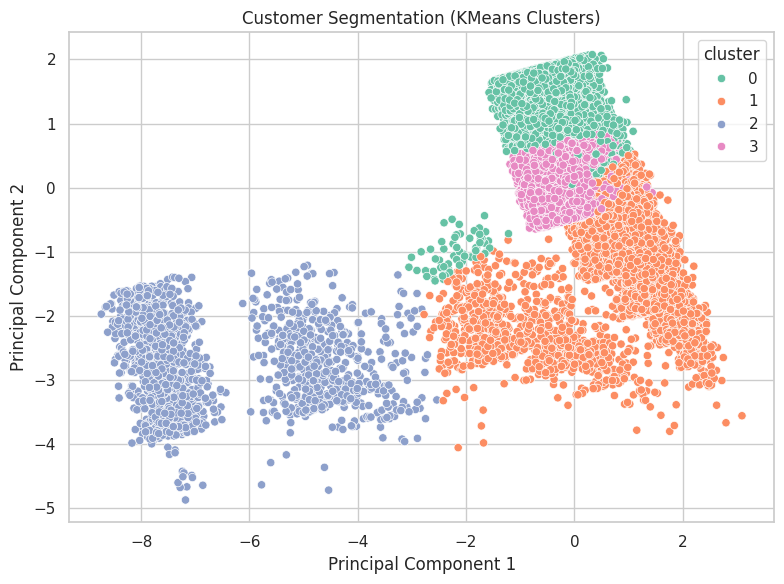

In [466]:
# Visualize customer clusters using PCA

pca = PCA(n_components = 2)
components = pca.fit_transform(X_scaled)

buyer_cluster['pca1'] = components[:, 0]
buyer_cluster['pca2'] = components[:, 1]

plt.figure(figsize = (8, 6))

sns.scatterplot(
    data = buyer_cluster,
    x = 'pca1',
    y = 'pca2',
    hue = 'cluster',
    palette = 'Set2'
)

plt.title('Customer Segmentation (KMeans Clusters)')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')

plt.tight_layout()
plt.show()

### Cluster Interpretation

- **Cluster 0 (19,572 customers)**: Longest average recency (823 days), low average frequency (1.11) and average monetary value (104.78). This group may need re-engagement, although its purchase recency suggests many are inactive.
- **Cluster 1 (20,847 customers)**: Average frequency (2.43) and monetary value (229.71) are highest among the clusters, making this the strongest purchasing-value group in this clustering.
- **Cluster 2 (1,713 customers)**: Negative average monetary value (-91.88) and a very high average refund rate (81.20%) identify a small, high-risk group that merits refund and transaction-quality review.
- **Cluster 3 (17,959 customers)**: Average recency is 271 days, frequency is 1.00, monetary value is 94.20, and refund rate is 0%. These are relatively low-frequency buyers who may be candidates for second-purchase campaigns.
  
Cluster labels are descriptive interpretations of the observed feature averages; they are not inherent meanings of the K-Means cluster IDs.

## Module Summary

### Key findings:
- RFM segmentation separates high-value customers, low-engagement customers, potential loyalists, and customers with elevated refund risk.
- CLV segmentation shows a clear value gradient: the High segment averages `$329.78` in adjusted CLV versus `$22.83` in the Low segment. The Low segment also has the highest average refund rate (10.59%).
- K-Means provides a complementary behavioral view: one cluster has higher frequency and monetary value, while another small cluster has strongly negative monetary value and unusually high refunds.
- These segments can support differentiated actions: protect valuable customers, reactivate low-engagement buyers, and investigate refund-heavy accounts.
  
The next module evaluates repeat purchasing and inactivity. Note that CLV here is based on observed historical data and should not be interpreted as a guaranteed forecast of future revenue.

# Module 3: Customer Behavior & Retention

This module examines customer retention over time, identifies churned customers, and explores the factors associated with customer retention.

## Key questions:
- Who stays and who leaves?
- Which customer groups are more likely to churn?
- What factors are associated with customer retention?

## 3.1 Cohort Analysis

Cohort analysis tracks customer retention based on the month of first purchase.

This analysis helps evaluate how customer retention changes over time across different customer cohorts.

In [467]:
# Create customer cohorts based on first purchase month

cohort_df = transactions.merge(customers, on = 'customer_id', how = 'left')

cohort_df['cohort_month'] = cohort_df.groupby('customer_id')['timestamp'].transform('min').dt.to_period('M')
cohort_df['order_month'] = cohort_df['timestamp'].dt.to_period('M')

# Calculate the number of months since the customer's first purchase
cohort_df['cohort_index'] = (
    (cohort_df['order_month'].dt.year - cohort_df['cohort_month'].dt.year) * 12 +
    (cohort_df['order_month'].dt.month - cohort_df['cohort_month'].dt.month)
)

In [468]:
# Count unique customers in each cohort for each cohort month index
cohort_data = cohort_df.groupby(
    ['cohort_month', 'cohort_index']
)['customer_id'].nunique().reset_index(name = 'customers')

# Calculate the initial cohort size
cohort_size = (
    cohort_df[cohort_df['cohort_index'] == 0]
    .groupby('cohort_month')['customer_id']
    .nunique()
)

In [469]:
# Build the cohort retention matrix

cohort_pivot  = cohort_data.pivot_table(
    index = 'cohort_month',
    columns = 'cohort_index',
    values = 'customers',
)

cohort_pivot = cohort_pivot.sort_index(axis = 1)

retention = cohort_pivot.divide(
    cohort_size,
    axis = 0
)

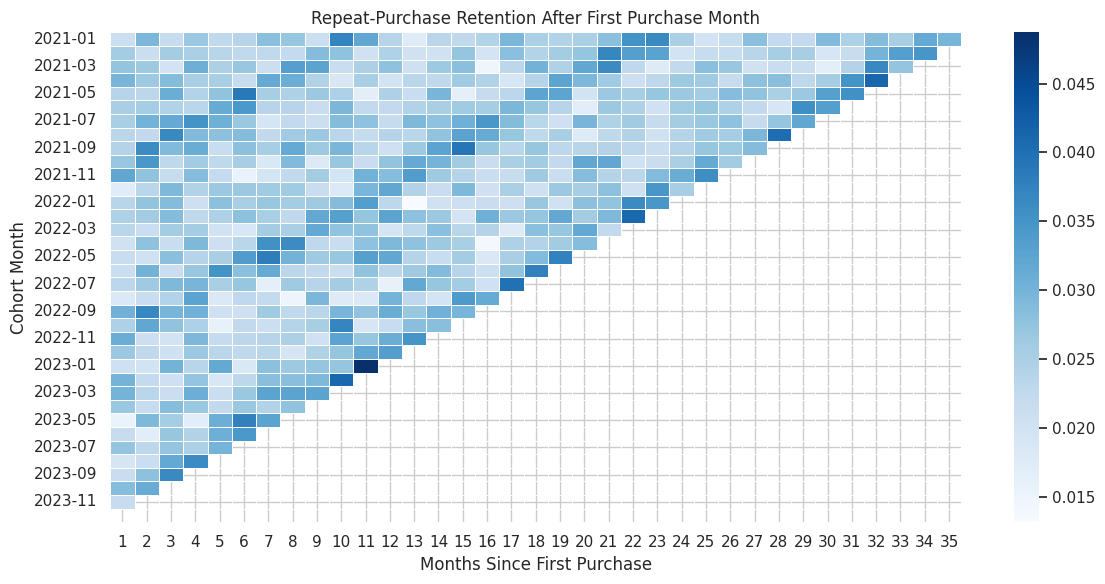

In [470]:
# Visualize customer retention using a cohort heatmap

retention_after_first_month = retention.iloc[:, 1:]

plt.figure(figsize = (12, 6))

sns.heatmap(
    retention_after_first_month,
    annot = False,
    fmt = '.1%',
    cmap = 'Blues',
    linewidths = 0.5
)

plt.title('Repeat-Purchase Retention After First Purchase Month')
plt.xlabel('Months Since First Purchase')
plt.ylabel('Cohort Month')

plt.tight_layout()
plt.show()

In [471]:
# Preview the cohort retention matrix

retention.round(3)

cohort_index,0,1,2,3,4,5,6,7,8,9,...,26,27,28,29,30,31,32,33,34,35
cohort_month,,,,,,,,,,,,,,,,,,,,,
2021-01,1.0,0.021,0.030,0.022,0.027,0.023,0.024,0.028,0.027,0.021,...,0.022,0.028,0.022,0.022,0.029,0.025,0.029,0.025,0.032,0.03
2021-02,1.0,0.026,0.021,0.026,0.025,0.024,0.023,0.023,0.022,0.029,...,0.022,0.024,0.025,0.025,0.019,0.022,0.030,0.033,0.035,NaN
2021-03,1.0,0.027,0.027,0.020,0.031,0.025,0.027,0.021,0.033,0.033,...,0.027,0.020,0.022,0.022,0.017,0.024,0.037,0.027,NaN,NaN
2021-04,1.0,0.030,0.027,0.029,0.025,0.025,0.022,0.032,0.031,0.024,...,0.022,0.028,0.028,0.023,0.026,0.035,0.041,NaN,NaN,NaN
2021-05,1.0,0.024,0.023,0.031,0.024,0.028,0.039,0.025,0.025,0.027,...,0.028,0.028,0.025,0.027,0.033,0.035,NaN,NaN,NaN,NaN
2021-06,1.0,0.025,0.026,0.024,0.023,0.031,0.034,0.024,0.024,0.021,...,0.025,0.022,0.019,0.036,0.033,NaN,NaN,NaN,NaN,NaN
2021-07,1.0,0.025,0.030,0.032,0.035,0.031,0.027,0.019,0.023,0.021,...,0.028,0.022,0.027,0.032,NaN,NaN,NaN,NaN,NaN,NaN
2021-08,1.0,0.023,0.023,0.037,0.029,0.028,0.029,0.023,0.026,0.027,...,0.026,0.030,0.040,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2021-09,1.0,0.024,0.036,0.029,0.031,0.022,0.028,0.026,0.032,0.027,...,0.027,0.029,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### Key Findings

- Low early repeat-purchase retention: Month 1 retention is generally around 2%–3% across the displayed cohorts, indicating that relatively few first-time buyers return to purchase in the following month.
- Cohort variation exists: Month 1 retention differs modestly by cohort; comparisons should be made at the same cohort age because newer cohorts have less follow-up time.
- Activation and retention are distinct: A first purchase is only the start of the customer relationship. Post-purchase onboarding and second-order incentives may help improve repeat purchasing.
  
The cohort table measures repeat purchase by month relative to the first purchase; it should not be interpreted as event/session retention.

## 3.2 Churn Analysis

Customers are classified as retained or churned based on purchase inactivity.

A customer is considered churned if no purchase has been made within 90 days of the latest transaction date.

### Churn Dataset Construction

Prepare customer-level churn information for subsequent analysis.

In [472]:
# Calculate each customer's last purchase date

snapshot_date = transactions['timestamp'].max()

last_purchase = transactions.groupby('customer_id')['timestamp'].max().reset_index()

last_purchase.columns = ['customer_id', 'last_purchase_date']

last_purchase['days_since_last_purchase'] = (
    snapshot_date - last_purchase['last_purchase_date']
).dt.days

last_purchase['churn'] = last_purchase['days_since_last_purchase'] > 90

In [473]:
# Merge churn information with customer profiles

churn_df = customers.merge(last_purchase, 
                           on = 'customer_id', 
                           how = 'left')

churn_df['buyer_flag'] = (
    churn_df['last_purchase_date'].notna()
)

In [474]:
# Classify customers by churn status

def churn_status(row):
    if not row['buyer_flag']:
        return 'Never Purchased'
    elif row['churn']:
        return 'Churned'
    else:
        return 'Retained'

churn_df['churn_status'] = churn_df.apply(churn_status, axis = 1)

churn_df['retained_flag'] = (
    churn_df['churn_status'] == 'Retained'
)

In [475]:
# Calculate activation and churn rates

activation_rate = churn_df['buyer_flag'].mean()

print(f'Activation Rate: {activation_rate:.2%}')

buyers_churn = churn_df[churn_df['buyer_flag']]

churn_rate = buyers_churn['churn'].mean()

print(f'Churn Rate: {churn_rate:.2%}')

Activation Rate: 60.09%
Churn Rate: 85.90%


### Churn Analysis by Customer Segment

Compare churn rates across different customer groups.

In [476]:
# Summarize overall customer churn status

status = (
    churn_df['churn_status']
    .value_counts(normalize = True)
    .mul(100)
    .round(2)
    .reset_index()
)

status.columns = ['Churn Status', 'Percentage (%)']

display(status)

,Churn Status,Percentage (%)
0,Churned,51.62
1,Never Purchased,39.91
2,Retained,8.47


In [477]:
# Compare churn rates across acquisition channels

buyers_churn = buyers_churn.copy()
buyers_churn['churn'] = buyers_churn['churn'].astype(bool)

result = (
    buyers_churn.groupby('acquisition_channel')['churn']
    .mean()
    .sort_values(ascending = False)
    .mul(100)
    .round(2)
    .rename('Churn Rate (%)')
    .reset_index()
)

display(result)

,acquisition_channel,Churn Rate (%)
0,Referral,86.52
1,Email,86.16
2,Paid Search,85.92
3,Organic,85.79
4,Social,85.43


In [478]:
# Compare churn rate across loyalty segments

result = (
    buyers_churn.groupby('loyalty_tier')['churn']
    .mean()
    .mul(100)
    .round(2)
    .rename('Churn Rate (%)')
    .reset_index()
)

display(result)

,loyalty_tier,Churn Rate (%)
0,Bronze,86.50
1,Gold,84.79
2,Platinum,83.77
3,Silver,85.51


In [479]:
# Analyze geographic differences in churn behavior

result = (
    buyers_churn.groupby('country')['churn']
    .mean()
    .sort_values(ascending = False)
    .mul(100)
    .round(2)
    .rename('Churn Rate (%)')
    .reset_index()
)

display(result)

,country,Churn Rate (%)
0,BR,86.36
1,CA,86.18
2,AU,86.12
3,US,86.08
4,UK,85.91
5,IN,85.53
6,DE,84.96


In [480]:
# Segment customers into age groups and compare churn rates

buyers_churn['age_group'] = pd.cut(
    buyers_churn['age'],
    bins = [0, 25, 35, 45, 60, 100]
)

result = (
    buyers_churn.groupby('age_group', observed=True)['churn']
    .mean()
    .mul(100)
    .round(2)
    .rename('Churn Rate (%)')
    .reset_index()
    .sort_values(by='Churn Rate (%)', ascending = False)
)

display(result)

,age_group,Churn Rate (%)
4,"(60, 100]",88.58
3,"(45, 60]",86.06
1,"(25, 35]",85.98
0,"(0, 25]",85.96
2,"(35, 45]",85.69


In [481]:
# Combine customer engagement metrics with churn labels
# Analyze whether user activity is associated with churn

event_activity = events.groupby('customer_id').agg({
    'event_id': 'count',
    'session_duration_sec': 'mean'
}).reset_index()

event_activity.columns = ['customer_id', 'event_count', 'avg_session_duration']

event_activity = event_activity.merge(buyers_churn[['customer_id', 'churn']],
                                     on = 'customer_id',
                                     how = 'left')

In [482]:
event_activity = event_activity.dropna(
    subset=['churn']
).copy()

event_activity['churn_status'] = event_activity['churn'].map({
    False: 'Retained',
    True: 'Churned'
})

event_activity_summary = (
    event_activity
    .groupby('churn_status')
    .agg(
        customers = ('customer_id', 'nunique'),
        avg_event_count = ('event_count', 'mean'),
        median_event_count = ('event_count', 'median'),
        avg_session_duration = ('avg_session_duration', 'mean')
    )
    .round(2)
    .reset_index()
)

display(event_activity_summary)

,churn_status,customers,avg_event_count,median_event_count,avg_session_duration
0,Churned,51621,20.54,20.0,130.65
1,Retained,8470,20.96,21.0,130.61


### Churn Visualization

Visualize the distribution of churn across customer groups.

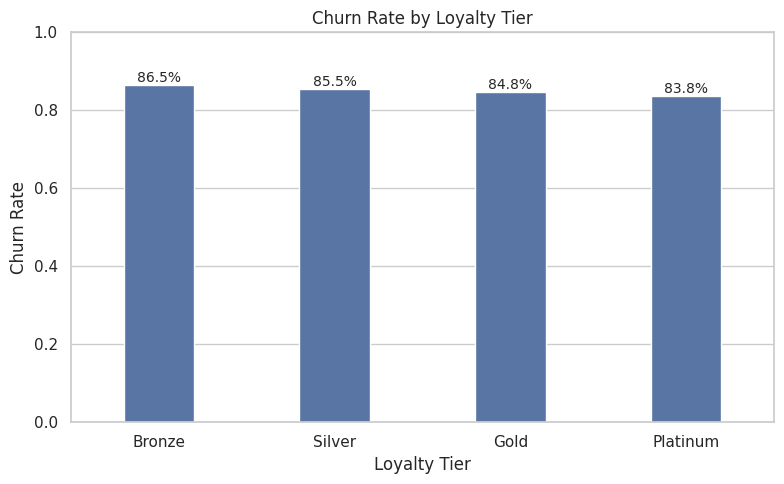

In [483]:
# Visualize churn rate by loyalty tier

plt.figure(figsize = (8, 5))

# Calculate churn rate by loyalty tier and sort in descending order
tier_order = (
    buyers_churn.groupby('loyalty_tier', observed = True)['churn']
    .mean()
    .sort_values(ascending = False)
    .index
)

ax = sns.barplot(
    data = buyers_churn,
    x = 'loyalty_tier',
    y = 'churn',
    order = tier_order,
    width = 0.4,
    errorbar = None
)

plt.title('Churn Rate by Loyalty Tier')
plt.xlabel('Loyalty Tier')
plt.ylabel('Churn Rate')

for p in ax.patches:
    height = p.get_height()
    ax.annotate(
        f'{height:.1%}',
        (p.get_x() + p.get_width() / 2, height),
        ha = 'center',
        va = 'bottom',
        fontsize = 10
    )

plt.ylim(0, 1)   
plt.tight_layout()
plt.show()

### Churn Analysis: Key Findings
- The customer-level status breakdown is 51.62% Churned, 39.91% Never Purchased, and 8.47% Retained across the full customer dataset.
- Among customers who have purchased, the rule-based churn rate is 85.90%, using the stated 90-day inactivity threshold.
- Churn rates differ only modestly by acquisition channel in this analysis (85.43%–86.52%). Platinum customers have a lower churn rate (83.77%) than Bronze customers (86.50%).
- These values depend on the chosen observation date and 90-day rule; they should be treated as descriptive classifications, not a validated forecast of future churn.

## 3.3 Retention Drivers

This section explores which customer characteristics are associated with customer retention.

The analysis compares retained and churned customers and applies logistic regression as an exploratory model.

### Retained vs Churned Customer Comparison

Compare customer characteristics between retained and churned buyers.

In [484]:
# Compare numerical characteristics between retained and churned buyers

num_cols = ['age', 'days_since_last_purchase']

churn_df['churn_status'] = churn_df['churn_status'].astype('category')

result = (
    churn_df.groupby('churn_status', observed = True)[num_cols]
    .mean()
    .reset_index()
)

display(result)

,churn_status,age,days_since_last_purchase
0,Churned,35.243719,524.723446
1,Never Purchased,35.190809,NaN
2,Retained,35.264581,41.652774


### Retention Analysis Across Customer Segments

Analyze retention differences across customer attributes.

In [485]:
# Compare retention rates across customer segments

# Acquisition Channel
display(
    buyers_churn.groupby('acquisition_channel')['retained_flag']
    .mean()
    .sort_values(ascending = False)
    .reset_index(name = 'Retention Rate')
)

# Country
display(
    buyers_churn.groupby('country')['retained_flag']
    .mean()
    .sort_values(ascending = False)
    .reset_index(name = 'Retention Rate')
)

# Gender
display(
    buyers_churn.groupby('gender')['retained_flag']
    .mean()
    .sort_values(ascending = False)
    .reset_index(name = 'Retention Rate')
)

# Loyalty Tier
display(
    buyers_churn.groupby('loyalty_tier')['retained_flag']
    .mean()
    .sort_values(ascending = False)
    .reset_index(name = 'Retention Rate')
)

# Age
buyers_churn['age_bin'] = pd.cut(buyers_churn['age'], bins=5)

display(
    buyers_churn.groupby('age_bin', observed = True)['retained_flag']
    .mean()
    .sort_values(ascending = False)
    .reset_index(name = 'Retention Rate')
)

# Churn Status
display(
    churn_df.groupby('churn_status', observed = True)['days_since_last_purchase']
    .mean()
    .reset_index(name = 'avg_days_since_last_purchase')
)

,acquisition_channel,Retention Rate
0,Social,0.145656
1,Organic,0.142065
2,Paid Search,0.140777
3,Email,0.138443
4,Referral,0.134815


,country,Retention Rate
0,DE,0.150413
1,IN,0.144743
2,UK,0.140868
3,US,0.139189
4,AU,0.138817
5,CA,0.138248
6,BR,0.136394


,gender,Retention Rate
0,Female,0.141327
1,Male,0.140845
2,Other,0.137697


,loyalty_tier,Retention Rate
0,Platinum,0.162316
1,Gold,0.152142
2,Silver,0.144893
3,Bronze,0.135048


,age_bin,Retention Rate
0,"(38.8, 49.2]",0.145261
1,"(17.948, 28.4]",0.139842
2,"(28.4, 38.8]",0.139822
3,"(49.2, 59.6]",0.133787
4,"(59.6, 70.0]",0.131579


,churn_status,avg_days_since_last_purchase
0,Churned,524.723446
1,Never Purchased,NaN
2,Retained,41.652774


### Retention Visualization

Visualize retention rate across customer segments.

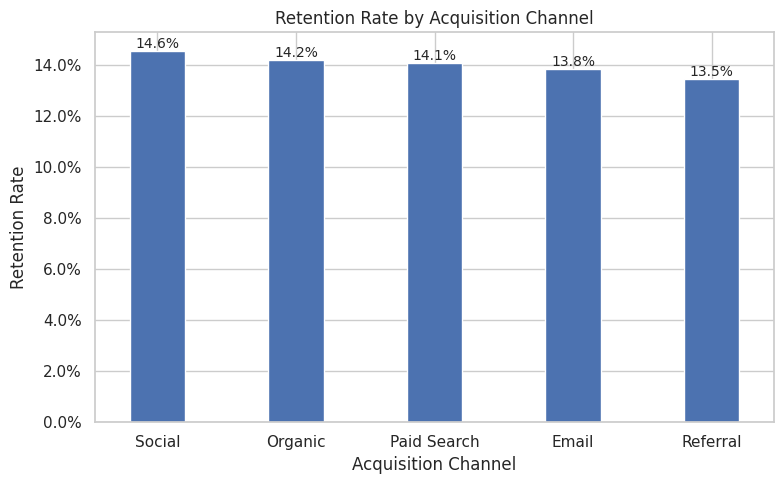

In [486]:
# Visualize retention rate by acquisition channel

retention_channel = (
    buyers_churn
    .groupby('acquisition_channel')['retained_flag']
    .mean()
    .sort_values(ascending = False)
)

ax = retention_channel.plot(
    kind = 'bar',
    figsize = (8, 5),
    width = 0.4
)

plt.title('Retention Rate by Acquisition Channel')
plt.xlabel('Acquisition Channel')
plt.ylabel('Retention Rate')

ax.yaxis.set_major_formatter(mticker.PercentFormatter(1.0))

for p in ax.patches:
    height = p.get_height()
    ax.annotate(
        f'{height:.1%}',
        (p.get_x() + p.get_width() / 2, height),
        ha = 'center',
        va = 'bottom',
        fontsize = 10
    )

plt.xticks(rotation = 0)
plt.tight_layout()
plt.show()

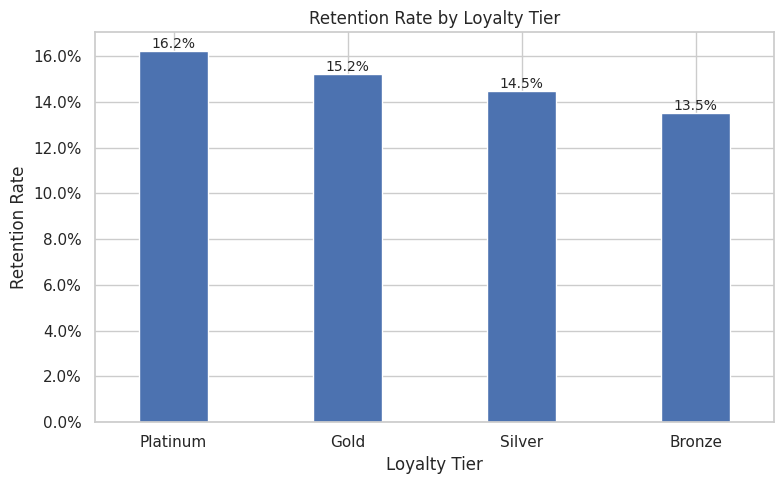

In [487]:
# Visualize retention rate by loyalty tier

retention_loyalty = (
    buyers_churn
    .groupby('loyalty_tier')['retained_flag']
    .mean()
    .sort_values(ascending = False)
)

ax = retention_loyalty.plot(
    kind = 'bar',
    figsize = (8, 5),
    width = 0.4
)

plt.title('Retention Rate by Loyalty Tier')
plt.xlabel('Loyalty Tier')
plt.ylabel('Retention Rate')

ax.yaxis.set_major_formatter(
    mticker.PercentFormatter(1.0)
)

for p in ax.patches:
    height = p.get_height()
    ax.annotate(
        f'{height:.1%}',
        (p.get_x() + p.get_width() / 2, height),
        ha = 'center',
        va = 'bottom',
        fontsize = 10
    )

plt.xticks(rotation = 0)
plt.tight_layout()

plt.show()

### Logistic Regression for Retention Drivers

A logistic regression model is used as an exploratory method to identify customer attributes associated with retention.

This model is not used for causal inference, but helps identify potential retention-related factors.

In [488]:
# Train a logistic regression model to identify factors associated with customer retention.

y = (buyers_churn['churn_status'] == 'Retained').astype(int)

X = buyers_churn[
    [
        'age',
        'loyalty_tier',
        'acquisition_channel',
        'gender',
        'country'
    ]
].copy()

X = pd.get_dummies(X, drop_first = True)
X = X.fillna(0)

# Standardize age
scaler = StandardScaler()
X['age'] = scaler.fit_transform(X[['age']])

model = LogisticRegression(
    max_iter = 1000,
    random_state = 42
)

model.fit(X, y)

coef_df = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': model.coef_[0]
})

coef_df['Odds Ratio'] = np.exp(coef_df['Coefficient'])

coef_df = coef_df.sort_values(
    by = 'Coefficient',
    ascending = False
)

display(coef_df)

,Feature,Coefficient,Odds Ratio
2,loyalty_tier_Platinum,0.193123,1.213032
1,loyalty_tier_Gold,0.136330,1.146060
12,country_DE,0.089424,1.093545
3,loyalty_tier_Silver,0.079160,1.082378
7,acquisition_channel_Social,0.067310,1.069627
13,country_IN,0.043681,1.044649
4,acquisition_channel_Organic,0.036386,1.037056
5,acquisition_channel_Paid Search,0.025509,1.025837
14,country_UK,0.012235,1.012310
0,age,0.001928,1.001930


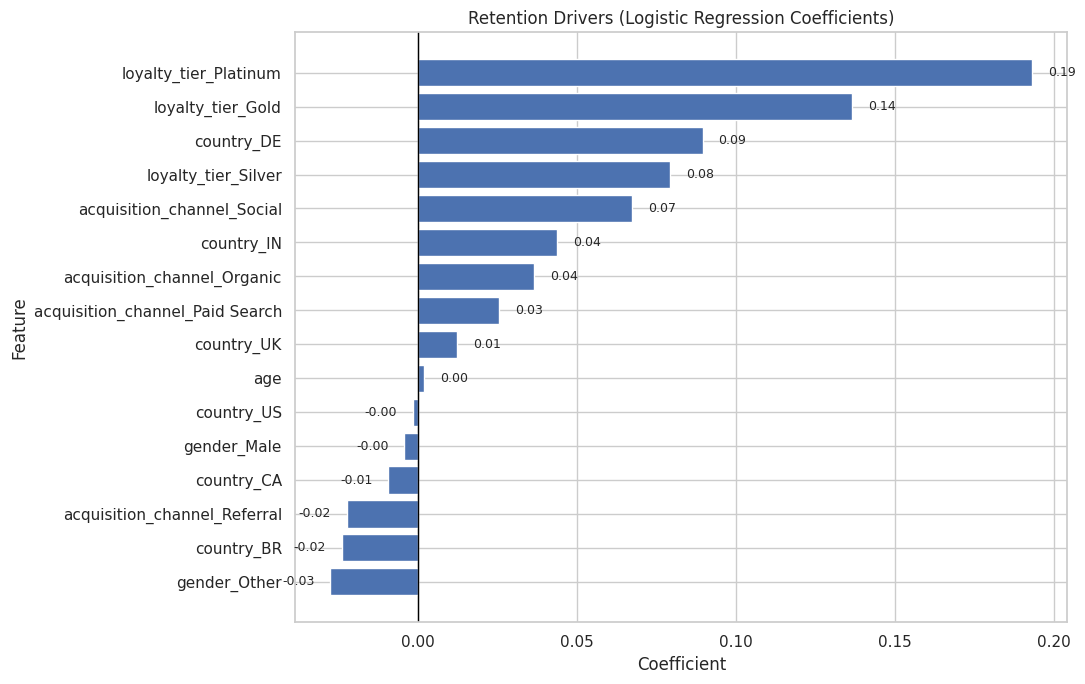

In [489]:
# Train the logistic regression model

coef_df = coef_df.sort_values('Coefficient')

plt.figure(figsize = (11, 7))

bars = plt.barh(
    coef_df['Feature'],
    coef_df['Coefficient']
)

# Zero reference line
plt.axvline(
    x = 0,
    color = 'black',
    linewidth = 1
)

# Add coefficient labels
for bar in bars:
    width = bar.get_width()
    plt.text(
        width + 0.005 if width >= 0 else width - 0.005,
        bar.get_y() + bar.get_height() / 2,
        f'{width:.2f}',
        va = 'center',
        ha = 'left' if width >= 0 else 'right',
        fontsize = 9
    )

plt.title('Retention Drivers (Logistic Regression Coefficients)')
plt.xlabel('Coefficient')
plt.ylabel('Feature')

plt.tight_layout()
plt.show()

## Module Summary

### Key findings:
- Activation rate is 60.09%: approximately 60% of customers in the churn dataset have made at least one purchase; 39.91% have never purchased.
- Among buyers, the 90-day inactivity rule classifies 85.90% as churned. This is a rule-based, historical inactivity measure, not a prediction of future churn.
- Retention varies by customer attributes, but the differences are modest in several dimensions. Platinum customers have the highest retention rate among loyalty tiers (16.23%), compared with 13.50% for Bronze customers.
- Retention by acquisition channel ranges from 13.48% for Referral to 14.57% for Social in the displayed buyer cohort.
- Logistic regression coefficients describe associations with retention, not causal effects. Loyalty tier and channel differences should be interpreted relative to the model's reference categories.
- Average event count and session duration are very similar for retained and churned customers in this dataset, so these two summary metrics alone do not clearly distinguish the groups.
  
The churn definition, observation window, and data coverage should be reviewed before using these rates as operational benchmarks.

# Module 4: Growth Drivers

This module evaluates customer acquisition, marketing campaign performance, and conversion funnel efficiency.

## Key questions:

- Which acquisition channels generate the highest-value customers?
- Which campaigns perform best?
- Where do customers drop off during the purchasing journey?

## 4.1 Acquisition Channel Analysis

This analysis evaluates acquisition channels based on:

- Customer acquisition volume
- Customer value (CLV and revenue)
- Purchase behavior
- Retention performance
- Customer quality

### Acquisition Dataset Preparation

Combine customer profile, purchasing behavior, customer value, and churn information into a unified dataset for channel analysis.

In [490]:
# Build the acquisition channel analysis dataset

acq = customers.copy()

acq = acq.merge(
    rfm[['customer_id',
         'frequency',
         'monetary',
         'recency']],
    on = 'customer_id',
    how = 'left'
)

acq = acq.merge(
    buyers[['customer_id',
           'adjusted_clv']],
    on = 'customer_id',
    how = 'left'
)

acq = acq.merge(
    churn_df[['customer_id',
              'churn',
              'buyer_flag']],
    on = 'customer_id',
    how = 'left'
)

In [491]:
# Handle missing values for customers without purchase history

acq['frequency'] = acq['frequency'].fillna(0)
acq['monetary'] = acq['monetary'].fillna(0)
acq['adjusted_clv'] = acq['adjusted_clv'].fillna(0)

acq['recency'] = acq['recency'].fillna(acq['recency'].max() + 1)

### Customer Acquisition Volume

Compare the number of customers acquired through each acquisition channel.

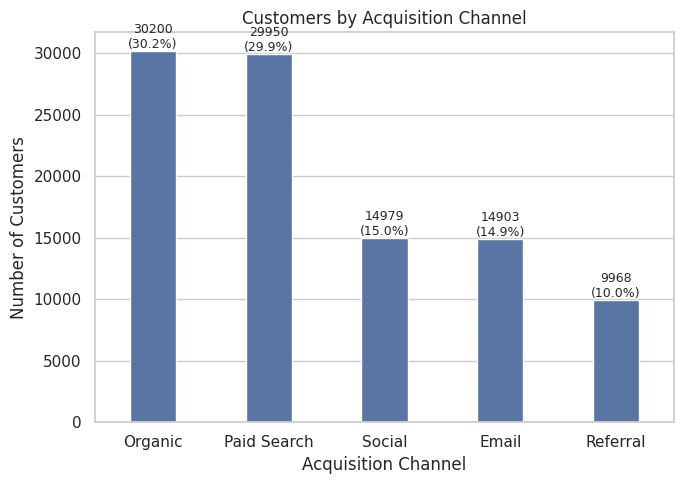

In [492]:
# Visualize customer acquisition volume by channel

plt.figure(figsize = (7, 5))

ax = sns.countplot(
    data = acq,
    x = 'acquisition_channel',
    order = acq['acquisition_channel'].value_counts().index,
    width = 0.4
)

plt.title('Customers by Acquisition Channel')
plt.xlabel('Acquisition Channel')
plt.ylabel('Number of Customers')

total = len(acq)

for p in ax.patches:
    count = int(p.get_height())
    percent = count / total * 100
    ax.annotate(
        f'{count}\n({percent:.1f}%)',
        (
            p.get_x() + p.get_width() / 2,
            p.get_height()
        ),
        ha = 'center',
        va = 'bottom',
        fontsize = 9
    )

plt.tight_layout()
plt.show()

### Customer Value by Acquisition Channel

Evaluate customer quality across acquisition channels using CLV, revenue, and purchase frequency.

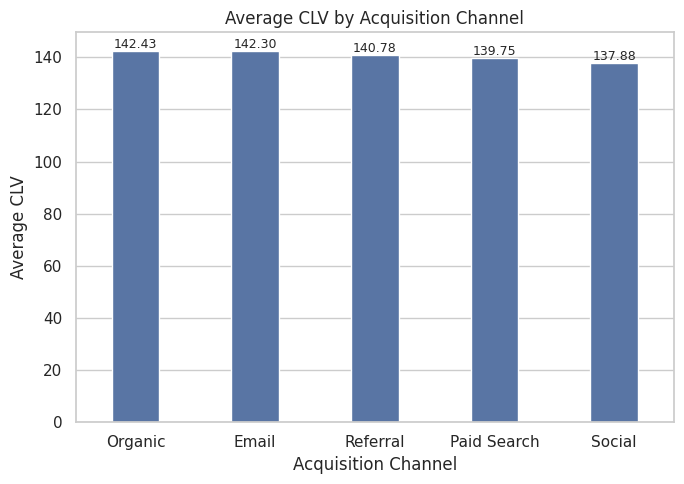

In [493]:
# Compare average CLV across acquisition channels

acq_buyers = acq[acq['buyer_flag']].copy()

channel_clv = (
    acq_buyers.groupby('acquisition_channel')['adjusted_clv']
    .mean()
    .sort_values(ascending = False)
)

plt.figure(figsize = (7, 5))

ax = sns.barplot(
    x = channel_clv.index,
    y = channel_clv.values,
    width = 0.4
)

plt.title('Average CLV by Acquisition Channel')
plt.xlabel('Acquisition Channel')
plt.ylabel('Average CLV')

# Add value labels
for p in ax.patches:
    height = p.get_height()
    ax.annotate(
        f'{height:.2f}',
        (p.get_x() + p.get_width() / 2, height),
        ha = 'center',
        va = 'bottom',
        fontsize = 9
    )

plt.tight_layout()
plt.show()

### Average Revenue

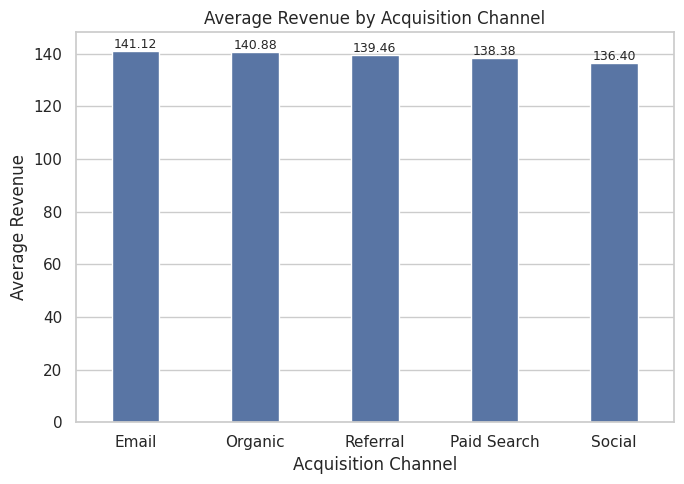

In [494]:
# Compare average revenue across acquisition channels

channel_rev = (
    acq_buyers.groupby('acquisition_channel')['monetary']
    .mean()
    .sort_values(ascending = False)
)

plt.figure(figsize = (7, 5))

ax = sns.barplot(
    x = channel_rev.index,
    y = channel_rev.values,
    width = 0.4
)

plt.title('Average Revenue by Acquisition Channel')
plt.xlabel('Acquisition Channel')
plt.ylabel('Average Revenue')

# Add value labels
for p in ax.patches:
    height = p.get_height()
    ax.annotate(
        f'{height:.2f}',      
        (p.get_x() + p.get_width() / 2, height),
        ha = 'center',
        va = 'bottom',
        fontsize = 9
    )

plt.tight_layout()
plt.show()

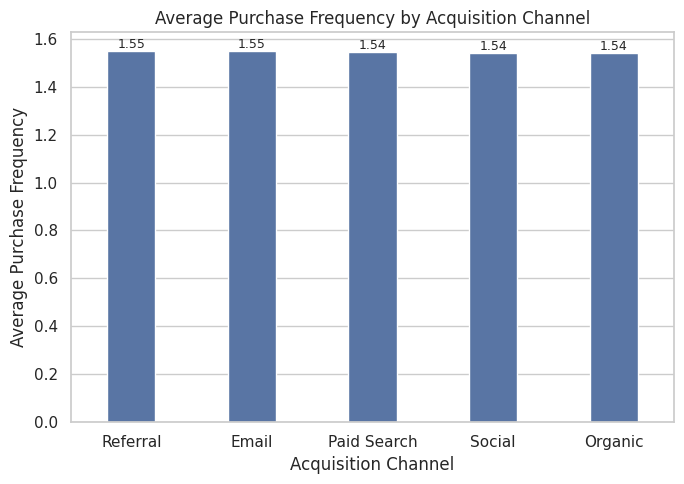

In [495]:
# Compare average purchase frequency across acquisition channels

channel_freq = (
    acq_buyers.groupby('acquisition_channel')['frequency']
    .mean()
    .sort_values(ascending = False)
)

plt.figure(figsize = (7, 5))

ax = sns.barplot(
    x = channel_freq.index,
    y = channel_freq.values,
    width = 0.4
)

plt.title('Average Purchase Frequency by Acquisition Channel')
plt.xlabel('Acquisition Channel')
plt.ylabel('Average Purchase Frequency')

# Add value labels
for p in ax.patches:
    height = p.get_height()
    ax.annotate(
        f'{height:.2f}',
        (p.get_x() + p.get_width() / 2, height),
        ha = 'center',
        va = 'bottom',
        fontsize = 9
    )

plt.tight_layout()
plt.show()


### Retention Performance

Evaluate customer retention and churn across acquisition channels.

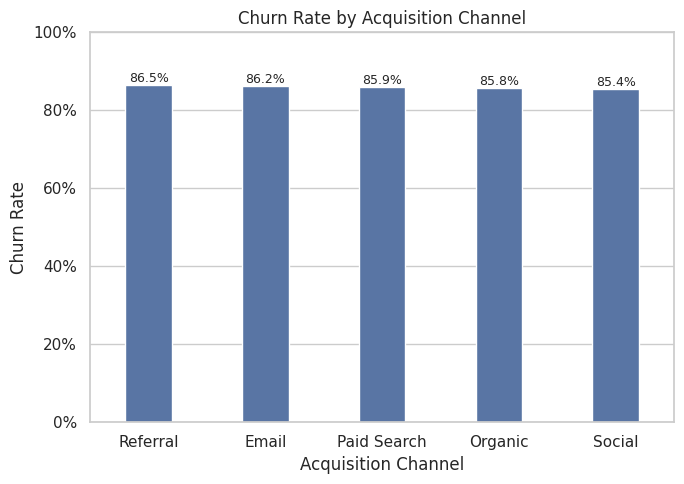

In [496]:
# Compare churn rates across acquisition channels

channel_churn = (
    acq_buyers.groupby('acquisition_channel')['churn']
    .mean()
    .sort_values(ascending = False)
)

plt.figure(figsize = (7, 5))

ax = sns.barplot(
    x = channel_churn.index,
    y = channel_churn.values,
    width = 0.4
)

plt.title('Churn Rate by Acquisition Channel')
plt.xlabel('Acquisition Channel')
plt.ylabel('Churn Rate')

# Display y-axis as percentages
ax.yaxis.set_major_formatter(
    mticker.PercentFormatter(1.0)
)

# Add percentage labels
for p in ax.patches:
    height = p.get_height()
    ax.annotate(
        f'{height:.1%}',
        (p.get_x() + p.get_width() / 2, height),
        ha = 'center',
        va = 'bottom',
        fontsize = 9
    )

plt.ylim(0, 1)
plt.tight_layout()

plt.show()

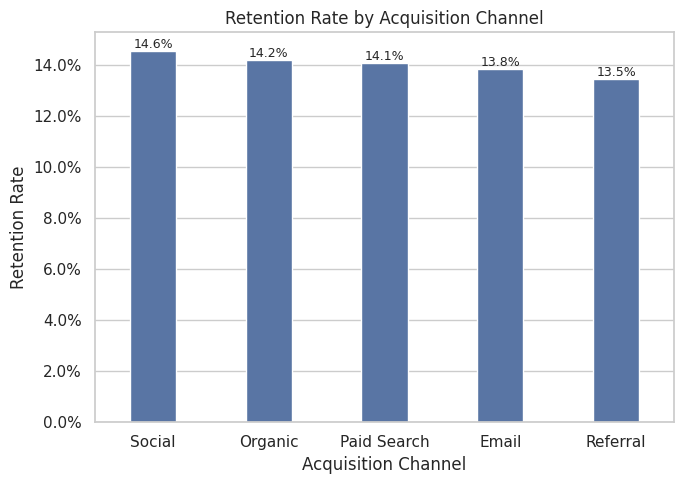

In [497]:
# Compare retention rates across acquisition channels

channel_retention = (
    buyers_churn.groupby('acquisition_channel')['retained_flag']
    .mean()
    .sort_values(ascending = False)
)

plt.figure(figsize = (7, 5))

ax = sns.barplot(
    x = channel_retention.index,
    y = channel_retention.values,
    width = 0.4
)

plt.title('Retention Rate by Acquisition Channel')
plt.xlabel('Acquisition Channel')
plt.ylabel('Retention Rate')

# Display y-axis as percentages
ax.yaxis.set_major_formatter(
    mticker.PercentFormatter(1.0)
)

# Add percentage labels
for p in ax.patches:
    height = p.get_height()
    ax.annotate(
        f'{height:.1%}',
        (p.get_x() + p.get_width() / 2, height),
        ha = 'center',
        va = 'bottom',
        fontsize = 9
    )

plt.tight_layout()
plt.show()

### Customer Quality Analysis

Evaluate customer quality using refund behavior and high-value customer ratio.

In [498]:
# Calculate customer refund rates

refund = (
    transactions
    .groupby('customer_id')
    .agg(
        refund_count = ('refund_flag', 'sum'),
        order_count = ('transaction_id', 'count')
    )
    .reset_index()
)

refund['refund_rate'] = (
    refund['refund_count'] / refund['order_count']
)

In [499]:
# Merge refund information into the acquisition dataset

acq_buyers = acq_buyers.merge(
    refund[['customer_id', 'refund_rate']],
    on = 'customer_id',
    how = 'left'
)

acq_buyers['refund_rate'] = acq_buyers['refund_rate'].fillna(0)

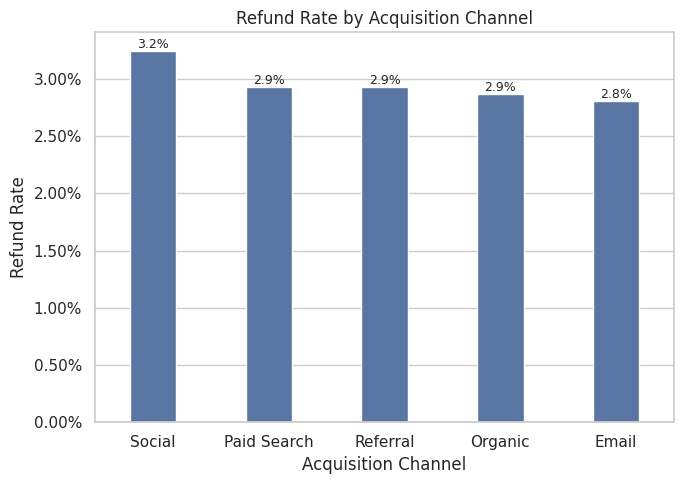

In [500]:
# Compare refund rates across acquisition channels

refund_channel = (
    acq_buyers.groupby('acquisition_channel')['refund_rate']
    .mean()
    .sort_values(ascending = False)
)

plt.figure(figsize = (7, 5))

ax = sns.barplot(
    x = refund_channel.index,
    y = refund_channel.values,
    width = 0.4
)

plt.title('Refund Rate by Acquisition Channel')
plt.xlabel('Acquisition Channel')
plt.ylabel('Refund Rate')

# Display y-axis as percentages
ax.yaxis.set_major_formatter(
    mticker.PercentFormatter(1.0)
)

# Add percentage labels
for p in ax.patches:
    height = p.get_height()
    ax.annotate(
        f'{height:.1%}',
        (p.get_x() + p.get_width() / 2, height),
        ha = 'center',
        va = 'bottom',
        fontsize = 9
    )

plt.tight_layout()
plt.show()

In [501]:
# Identify high-value customers

threshold = acq_buyers['adjusted_clv'].quantile(0.8)

acq_buyers['high_value'] = acq_buyers['adjusted_clv'] >= threshold

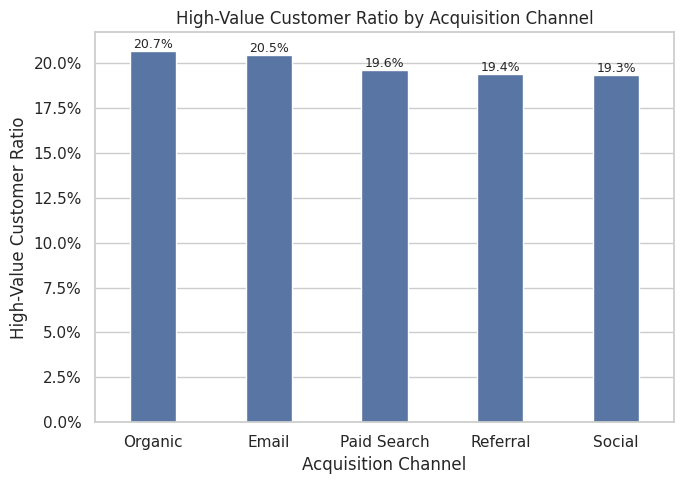

In [502]:
# Compare high-value customer ratio across acquisition channels

high_value = (
    acq_buyers.groupby('acquisition_channel')['high_value']
    .mean()
    .sort_values(ascending = False)
)

plt.figure(figsize = (7, 5))

ax = sns.barplot(
    x = high_value.index,
    y = high_value.values,
    width = 0.4
)

plt.title('High-Value Customer Ratio by Acquisition Channel')
plt.xlabel('Acquisition Channel')
plt.ylabel('High-Value Customer Ratio')

# Display y-axis as percentages
ax.yaxis.set_major_formatter(
    mticker.PercentFormatter(1.0)
)

# Add percentage labels
for p in ax.patches:
    height = p.get_height()
    ax.annotate(
        f'{height:.1%}',
        (p.get_x() + p.get_width() / 2, height),
        ha = 'center',
        va = 'bottom',
        fontsize = 9
    )

plt.tight_layout()
plt.show()

### Customer Value Distribution

Compare customer purchasing behavior distributions across acquisition channels.

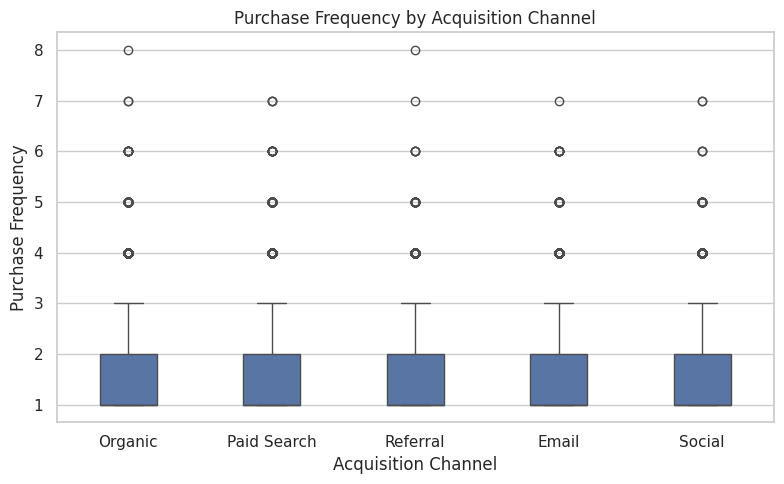

In [503]:
# Compare purchase frequency across acquisition channels

plt.figure(figsize = (8, 5))

sns.boxplot(
    data = acq_buyers,
    x = 'acquisition_channel',
    y = 'frequency',
    width = 0.4
)

plt.title('Purchase Frequency by Acquisition Channel')
plt.xlabel('Acquisition Channel')
plt.ylabel('Purchase Frequency')

plt.tight_layout()
plt.show()

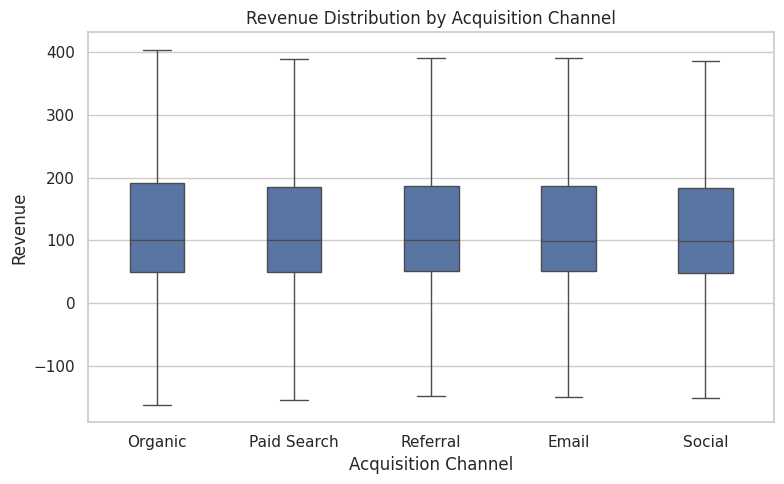

In [504]:
# Compare customer revenue across acquisition channels

plt.figure(figsize = (8, 5))

sns.boxplot(
    data  = acq_buyers,
    x = 'acquisition_channel',
    y = 'monetary',
    width = 0.4,
    showfliers = False
)

plt.title('Revenue Distribution by Acquisition Channel')
plt.xlabel('Acquisition Channel')
plt.ylabel('Revenue')

plt.tight_layout()
plt.show()

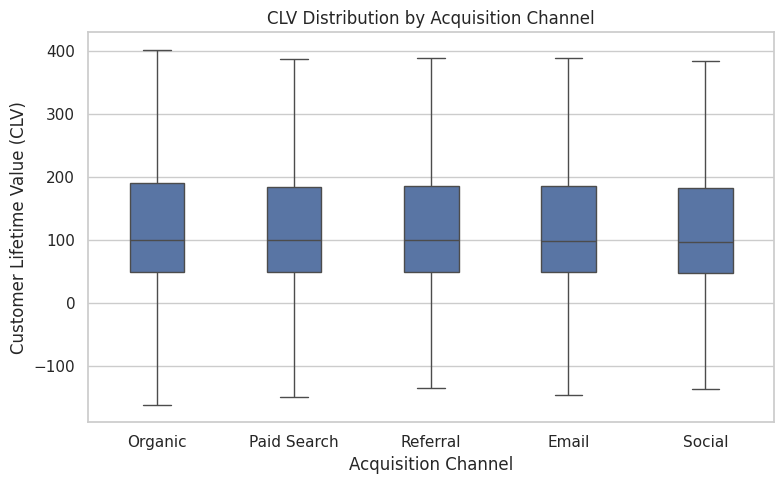

In [505]:
# Compare CLV across acquisition channels

plt.figure(figsize = (8, 5))

sns.boxplot(
    data = acq_buyers,
    x = 'acquisition_channel',
    y = 'adjusted_clv',
    width = 0.4,
    showfliers = False
)

plt.title('CLV Distribution by Acquisition Channel')
plt.xlabel('Acquisition Channel')
plt.ylabel('Customer Lifetime Value (CLV)')

plt.tight_layout()
plt.show()

### Acquisition Channel Summary

Summarize acquisition performance using customer volume, value, and retention metrics.

In [506]:
# Summarize acquisition channel performance

acq_buyers = acq_buyers.copy()
acq_buyers['churn'] = acq_buyers['churn'].astype(bool)

acquisition_channel_summary = (
    acq_buyers.groupby('acquisition_channel')
    .agg(
        Customers = ('customer_id', 'count'),
        Average_Frequency = ('frequency', 'mean'),
        Average_Revenue = ('monetary', 'mean'),
        Average_CLV = ('adjusted_clv', 'mean'),
        Churn_Rate = ('churn', 'mean')
    )
    .assign(
        Churn_Rate = lambda x: (x['Churn_Rate'] * 100).round(2)
    )
    .round({
        'Average_Frequency': 2,
        'Average_Revenue': 2,
        'Average_CLV': 2
    })
    .sort_values('Customers', ascending = False)
    .reset_index()
)

acquisition_channel_summary = acquisition_channel_summary.rename(
    columns = {'Churn_Rate': 'Churn Rate (%)'}
)

display(acquisition_channel_summary)

,acquisition_channel,Customers,Average_Frequency,Average_Revenue,Average_CLV,Churn Rate (%)
0,Organic,18210,1.54,140.88,142.43,85.79
1,Paid Search,18064,1.54,138.38,139.75,85.92
2,Social,8932,1.54,136.40,137.88,85.43
3,Email,8899,1.55,141.12,142.30,86.16
4,Referral,5986,1.55,139.46,140.78,86.52


### Key Findings

- In the analyzed acquisition data, Organic has the largest customer count (18,210) and the highest average CLV (142.43, narrowly ahead of Email at 142.30).
- Email has the highest average revenue (141.12) and average purchase frequency is very similar across channels (1.54–1.55).
- Social has the lowest churn rate among these channels (85.43%), while Referral has the highest (86.52%); the differences are relatively small.
- These results do not support choosing a channel on volume alone. Compare acquisition volume, average value, retention, and refund quality together, and validate whether channel attribution is mutually exclusive before treating customer counts as unique across channels.

## 4.2 Campaign Effectiveness Analysis

Evaluate campaign performance from customer engagement to revenue generation.

### Campaign Dataset Preparation

Prepare campaign-level engagement and transaction metrics.

In [507]:
# Calculate campaign engagement metrics

event_summary = (
    events.groupby('campaign_id')
    .agg(
        sessions = ('session_id', 'nunique'),
        events = ('event_id', 'count'),
        users = ('customer_id', 'nunique')
    )
    .reset_index()
)

In [508]:
# Calculate campaign revenue metrics

transaction_summary = (
    transactions.groupby('campaign_id')
    .agg(
        orders = ('transaction_id', 'count'),
        buyers = ('customer_id', 'nunique'),
        revenue = ('gross_revenue', 'sum')
    )
    .reset_index()
)

In [509]:
# Build campaign performance dataset

campaign_summary = campaigns.merge(
    event_summary,
    on = 'campaign_id',
    how = 'left'
)

campaign_summary = campaign_summary.merge(
    transaction_summary,
    on = 'campaign_id',
    how = 'left'
)

campaign_summary.fillna(0, inplace = True)

### Revenue Performance

Compare campaign performance based on generated revenue.

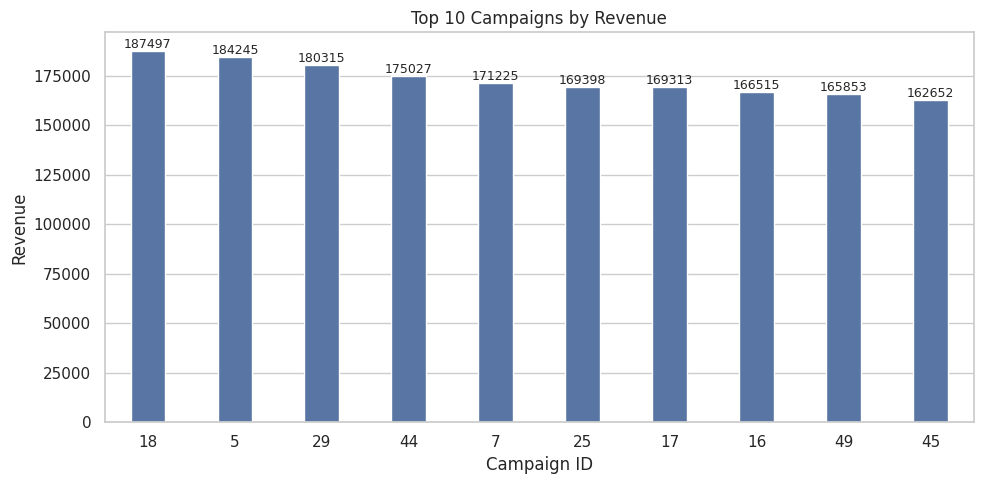

In [510]:
# Rank campaigns by revenue

top10_campaign = (
    campaign_summary
    .sort_values('revenue', ascending = False)
    .head(10)
)

plt.figure(figsize = (10, 5))

ax = sns.barplot(
    data = top10_campaign,
    x = 'campaign_id',
    y = 'revenue',
    order = top10_campaign['campaign_id'],
    width = 0.4
)

plt.title('Top 10 Campaigns by Revenue')
plt.xlabel('Campaign ID')
plt.ylabel('Revenue')

# Add value labels
for p in ax.patches:
    height = p.get_height()
    ax.annotate(
        f'{height:.0f}',
        (p.get_x() + p.get_width() / 2, height),
        ha = 'center',
        va = 'bottom',
        fontsize = 9
    )

plt.tight_layout()
plt.show()

### Conversion Performance

Evaluate campaign conversion efficiency.

In [511]:
# Calculate campaign conversion rates

campaign_summary['orders_per_session'] = (
    campaign_summary['orders']
    / campaign_summary['sessions']
)

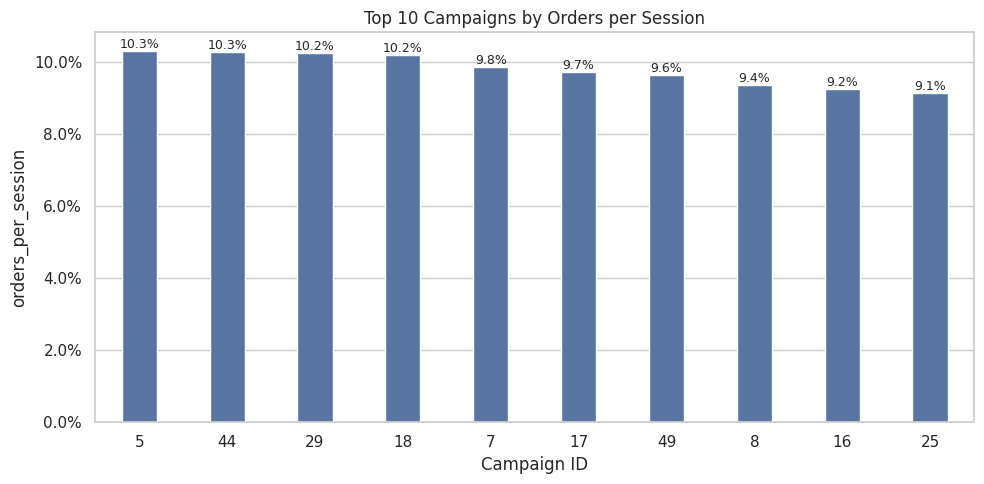

In [512]:
# Visualize campaign conversion performance

top10_conversion = (
    campaign_summary
    .sort_values('orders_per_session', ascending = False)
    .head(10)
)

plt.figure(figsize = (10, 5))

ax = sns.barplot(
    data = top10_conversion,
    x = 'campaign_id',
    y = 'orders_per_session',
    order = top10_conversion['campaign_id'],
    width = 0.4
)

plt.title('Top 10 Campaigns by Orders per Session')
plt.xlabel('Campaign ID')
plt.ylabel('orders_per_session')

# Display y-axis as percentages
ax.yaxis.set_major_formatter(
    mticker.PercentFormatter(1.0)
)

# Add percentage labels
for p in ax.patches:
    height = p.get_height()
    ax.annotate(
        f'{height:.1%}',
        (p.get_x() + p.get_width() / 2, height),
        ha = 'center',
        va = 'bottom',
        fontsize = 9
    )

plt.tight_layout()
plt.show()

### Revenue Efficiency

Measure revenue generated per customer session.

In [513]:
# Calculate revenue per session

campaign_summary['revenue_per_session'] = (
    campaign_summary['revenue']
    /
    campaign_summary['sessions']
)

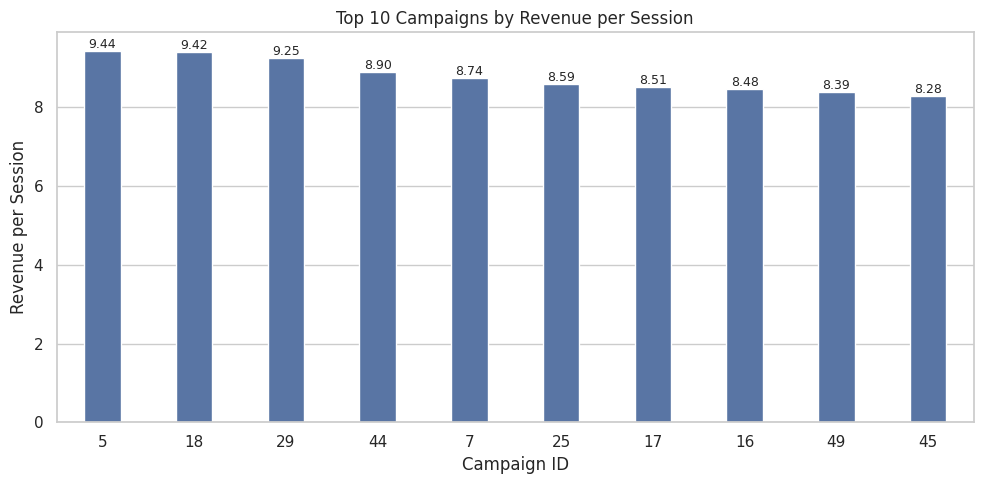

In [514]:
# Compare campaign revenue efficiency

top_efficiency = (
    campaign_summary
    .sort_values('revenue_per_session', ascending = False)
    .head(10)
)

plt.figure(figsize=(10, 5))

ax = sns.barplot(
    data = top_efficiency,
    x = 'campaign_id',
    y = 'revenue_per_session',
    order = top_efficiency['campaign_id'],
    width = 0.4
)

plt.title('Top 10 Campaigns by Revenue per Session')
plt.xlabel('Campaign ID')
plt.ylabel('Revenue per Session')

# Add value labels
for p in ax.patches:
    height = p.get_height()
    ax.annotate(
        f'{height:.2f}',
        (p.get_x() + p.get_width() / 2, height),
        ha = 'center',
        va = 'bottom',
        fontsize = 9
    )

plt.tight_layout()
plt.show()

### Marketing Channel Performance

Compare campaign effectiveness across marketing channels.

In [515]:
# Summarize campaign performance by marketing channel

campaign_channel_summary = (
    campaign_summary
    .groupby('channel')
    .agg(
        campaigns = ('campaign_id', 'count'),
        revenue = ('revenue', 'sum'),
        sessions = ('sessions', 'sum'),
        orders = ('orders', 'sum')
    )
)

campaign_channel_summary['conversion_rate'] = (
    campaign_channel_summary['orders']
    /
    campaign_channel_summary['sessions']
)

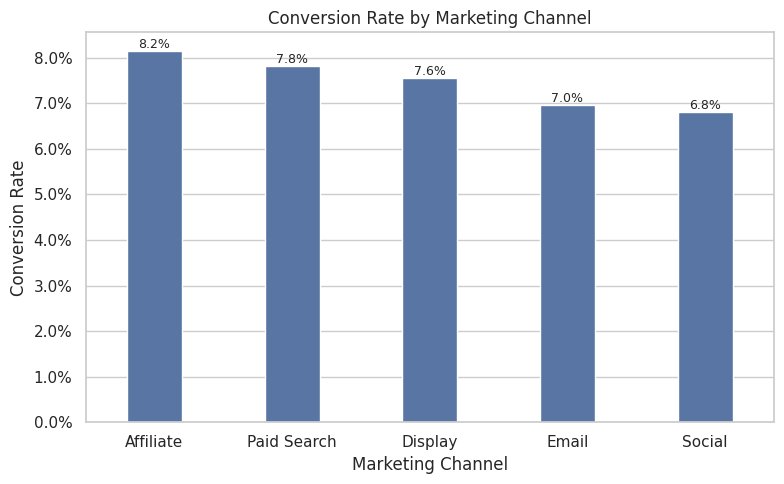

In [516]:
# Visualize conversion rate by marketing channel

plt.figure(figsize = (8, 5))

channel_conversion = (
    campaign_channel_summary
    .sort_values('conversion_rate', ascending = False)
)

ax = sns.barplot(
    data = channel_conversion,
    x = 'channel',
    y = 'conversion_rate',
    width = 0.4
)

plt.title('Conversion Rate by Marketing Channel')
plt.xlabel('Marketing Channel')
plt.ylabel('Conversion Rate')

# Display y-axis as percentages
ax.yaxis.set_major_formatter(
    mticker.PercentFormatter(1.0)
)

# Add percentage labels
for p in ax.patches:
    height = p.get_height()
    ax.annotate(
        f'{height:.1%}',
        (p.get_x() + p.get_width() / 2, height),
        ha = 'center',
        va = 'bottom',
        fontsize = 9
    )

plt.tight_layout()
plt.show()

### Campaign Objective Performance

Compare conversion performance across campaign objectives.

In [517]:
# Summarize campaign performance by objective

objective_summary = (
    campaign_summary
    .groupby('objective')
    .agg(
        revenue = ('revenue', 'sum'),
        orders = ('orders', 'sum'),
        sessions = ('sessions', 'sum')
    )
)

objective_summary['conversion_rate'] = (
    objective_summary['orders']
    /
    objective_summary['sessions']
)

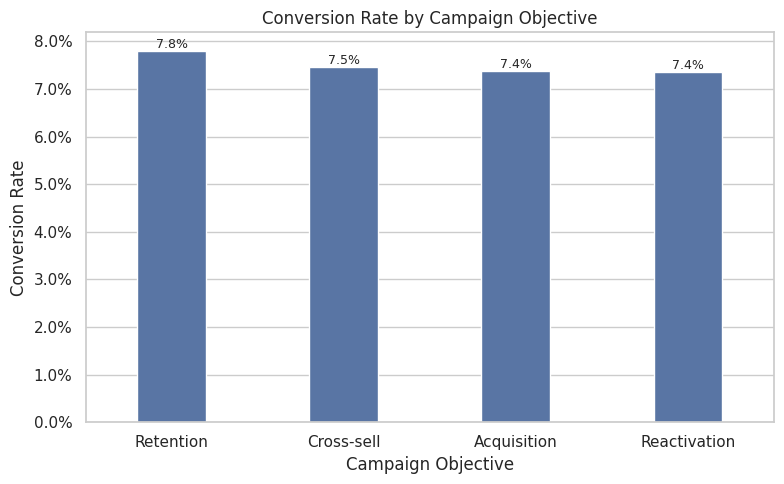

In [518]:
# Visualize campaign objectives

objective_conversion = (
    objective_summary
    .sort_values('conversion_rate', ascending = False)
)

plt.figure(figsize = (8, 5))

ax = sns.barplot(
    data = objective_conversion,
    x = 'objective',
    y = 'conversion_rate',
    width = 0.4
)

plt.title('Conversion Rate by Campaign Objective')
plt.xlabel('Campaign Objective')
plt.ylabel('Conversion Rate')

# Display y-axis as percentages
ax.yaxis.set_major_formatter(
    mticker.PercentFormatter(1.0)
)

# Add percentage labels
for p in ax.patches:
    height = p.get_height()
    ax.annotate(
        f'{height:.1%}',
        (p.get_x() + p.get_width() / 2, height),
        ha = 'center',
        va = 'bottom',
        fontsize = 9
    )

plt.tight_layout()
plt.show()

### Campaign Validation

Compare expected campaign uplift with actual campaign revenue.

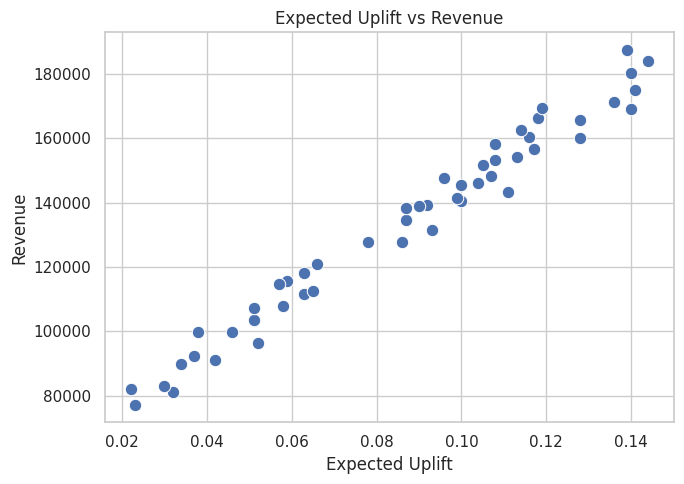

In [519]:
# Compare expected uplift and revenue

plt.figure(figsize = (7, 5))

sns.scatterplot(
    data = campaign_summary,
    x = 'expected_uplift',
    y = 'revenue',
    s = 80
)

plt.title('Expected Uplift vs Revenue')
plt.xlabel('Expected Uplift')
plt.ylabel('Revenue')

plt.tight_layout()
plt.show()

In [520]:
# Calculate the correlation between expected uplift and revenue

campaign_summary[
    ['expected_uplift','revenue']
].corr()

,expected_uplift,revenue
expected_uplift,1.000000,0.987145
revenue,0.987145,1.000000


### Product Impact

Evaluate premium product sales across campaign channels.

In [521]:
# Calculate premium product sales rate

campaign_sales = (
    transactions.merge(
        products,
        on = 'product_id'
    )
)

campaign_sales = campaign_sales.merge(
    campaigns[['campaign_id','channel']],
    on = 'campaign_id'
)

premium_rate = (
    campaign_sales
    .groupby('channel')['is_premium']
    .mean()
    .reset_index(name = 'premium_rate')
)

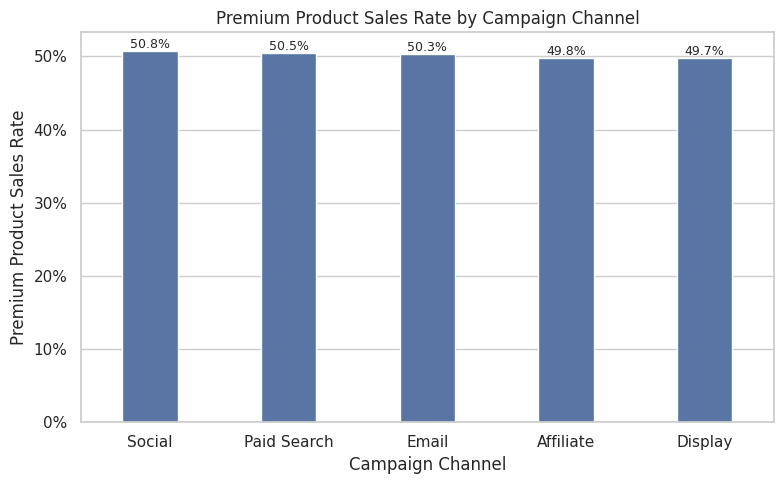

In [522]:
# Visualize premium product sales by campaign channel

plt.figure(figsize = (8, 5))

ax = sns.barplot(
    data = premium_rate.sort_values('premium_rate', ascending = False),
    x = 'channel',
    y = 'premium_rate',
    width = 0.4
)

plt.title('Premium Product Sales Rate by Campaign Channel')
plt.xlabel('Campaign Channel')
plt.ylabel('Premium Product Sales Rate')

# Display y-axis as percentages
ax.yaxis.set_major_formatter(
    mticker.PercentFormatter(1.0)
)

# Add percentage labels
for p in ax.patches:
    height = p.get_height()
    ax.annotate(
        f'{height:.1%}',
        (p.get_x() + p.get_width() / 2, height),
        ha = 'center',
        va = 'bottom',
        fontsize = 9
    )

plt.tight_layout()
plt.show()

### Campaign Summary

Summarize campaign performance across key business metrics.

In [523]:
# Summarize campaign performance

campaign_summary[
[
    'campaign_id',
    'channel',
    'objective',
    'users',
    'orders',
    'revenue',
    'orders_per_session',
    'revenue_per_session'
]
].sort_values(
    'revenue',
    ascending = False
)

,campaign_id,channel,objective,users,orders,revenue,orders_per_session,revenue_per_session
17,18,Affiliate,Retention,18313,2027,187497.20,0.101808,9.417238
4,5,Social,Acquisition,17944,2012,184244.86,0.103037,9.435390
28,29,Email,Acquisition,17976,1995,180315.11,0.102386,9.254047
43,44,Affiliate,Reactivation,18084,2019,175026.54,0.102696,8.902672
6,7,Paid Search,Cross-sell,18099,1929,171224.62,0.098484,8.741748
24,25,Paid Search,Cross-sell,18084,1804,169397.56,0.091476,8.589704
16,17,Display,Retention,18308,1934,169313.35,0.097249,8.513770
15,16,Email,Reactivation,18142,1815,166515.24,0.092418,8.478804
48,49,Paid Search,Reactivation,18215,1908,165853.45,0.096471,8.385754
44,45,Affiliate,Retention,18105,1754,162651.75,0.089312,8.282079


### Key Findings

- Campaign 18 has the highest observed revenue in the displayed campaign summary (`$187,497.20`), followed by Campaign 5 (`$184,244.86`) and Campaign 29 (`$180,315.11`). High total revenue alone does not establish cost-effectiveness because spend/cost is not included in these metrics.
- Campaign rankings differ when measured by orders per session or revenue per session, so campaign volume and efficiency should be reviewed separately.
- Expected uplift and revenue have a strong positive correlation in this dataset (r = 0.987). This is a descriptive correlation, not evidence that expected uplift causes revenue; it may also reflect how the synthetic campaign data was generated.
- Compare campaign performance with sample size and a clearly defined denominator before recommending budget changes.

## 4.3 Funnel Analysis

This analysis evaluates customer journey performance from initial interaction to purchase.

The goal is to:
- Understand overall conversion funnel
- Identify major drop-off stages
- Compare funnel performance across channels, devices, and campaigns

### Funnel Construction

Build the overall customer conversion funnel.

In [524]:
# Summarize user event distribution

result = (
    events['event_type']
    .value_counts()
    .rename('Count')
    .to_frame()
)

result['Percentage (%)'] = (
    result['Count']
    / result['Count'].sum()
    * 100
).round(2)

result = result.reset_index().rename(
    columns={'event_type': 'Event Type'}
)

display(result)

,Event Type,Count,Percentage (%)
0,view,1043573,52.18
1,click,379008,18.95
2,add_to_cart,284370,14.22
3,bounce,189922,9.50
4,purchase,103127,5.16


In [525]:
# Build the overall conversion funnel

funnel = (
    events[events['event_type'] != 'bounce']
    .groupby('event_type')['customer_id']
    .nunique()
    .reindex(['view', 'click', 'add_to_cart', 'purchase'])
    .reset_index(name = 'users')
)

funnel

,event_type,users
0,view,99997
1,click,97725
2,add_to_cart,94228
3,purchase,64035


### Funnel Visualization

Visualize customer movement across funnel stages.

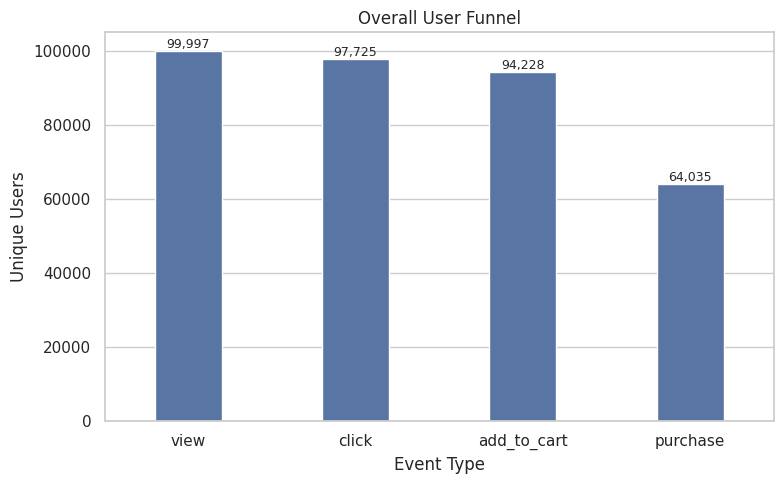

In [526]:
# Visualize the overall funnel

plt.figure(figsize = (8, 5))

ax = sns.barplot(
    data = funnel,
    x = 'event_type',
    y = 'users',
    width = 0.4
)

plt.title('Overall User Funnel')
plt.xlabel('Event Type')
plt.ylabel('Unique Users')

# Add value labels
for p in ax.patches:
    height = p.get_height()
    ax.annotate(
        f'{height:,.0f}',
        (p.get_x() + p.get_width() / 2, height),
        ha = 'center',
        va = 'bottom',
        fontsize = 9
    )

plt.tight_layout()
plt.show()

### Funnel Conversion Analysis

Evaluate conversion efficiency between funnel stages.

In [527]:
# Calculate funnel conversion rates

funnel['conversion_rate'] = funnel['users'] / funnel['users'].shift(1)
funnel.loc[0, 'conversion_rate'] = 1

funnel

,event_type,users,conversion_rate
0,view,99997,1.000000
1,click,97725,0.977279
2,add_to_cart,94228,0.964216
3,purchase,64035,0.679575


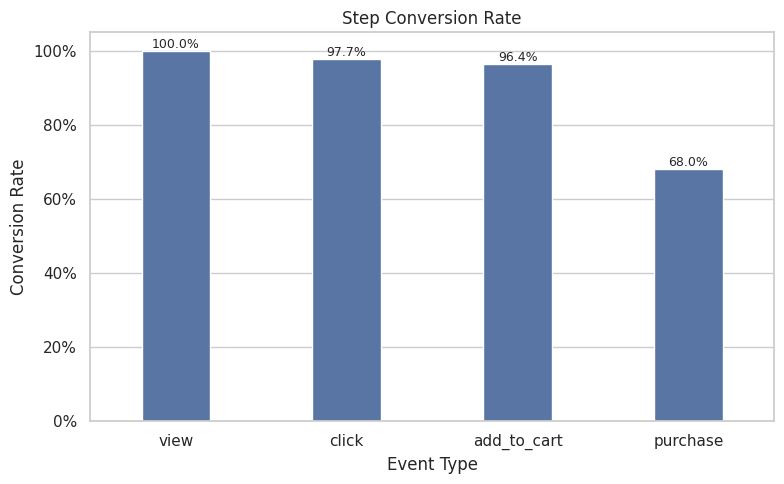

In [528]:
# Visualize funnel conversion rates

plt.figure(figsize = (8, 5))

ax = sns.barplot(
    data = funnel,
    x = 'event_type',
    y = 'conversion_rate',
    width = 0.4
)

plt.title('Step Conversion Rate')
plt.xlabel('Event Type')
plt.ylabel('Conversion Rate')

# Display y-axis as percentages
ax.yaxis.set_major_formatter(
    mticker.PercentFormatter(1.0)
)

# Add percentage labels
for p in ax.patches:
    height = p.get_height()
    ax.annotate(
        f'{height:.1%}',
        (p.get_x() + p.get_width() / 2, height),
        ha = 'center',
        va = 'bottom',
        fontsize = 9
    )

plt.tight_layout()
plt.show()

### Funnel Drop-off Analysis

Identify where customers leave the purchase journey.

In [529]:
# Calculate funnel drop-off rates

funnel['dropoff_rate'] = 1 - funnel['conversion_rate']
funnel

,event_type,users,conversion_rate,dropoff_rate
0,view,99997,1.000000,0.000000
1,click,97725,0.977279,0.022721
2,add_to_cart,94228,0.964216,0.035784
3,purchase,64035,0.679575,0.320425


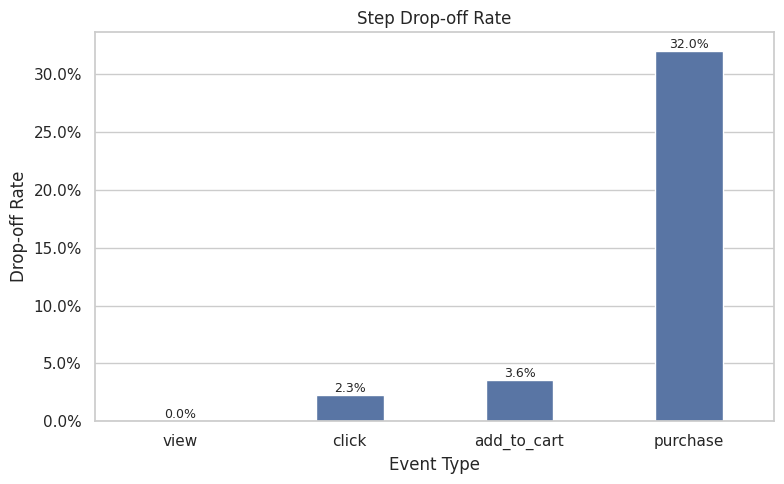

In [530]:
# Visualize funnel drop-off rates

plt.figure(figsize = (8, 5))

ax = sns.barplot(
    data = funnel,
    x = 'event_type',
    y = 'dropoff_rate',
    width = 0.4
)

plt.title('Step Drop-off Rate')
plt.xlabel('Event Type')
plt.ylabel('Drop-off Rate')

# Display y-axis as percentages
ax.yaxis.set_major_formatter(
    mticker.PercentFormatter(1.0)
)

# Add percentage labels
for p in ax.patches:
    height = p.get_height()
    ax.annotate(
        f'{height:.1%}',
        (p.get_x() + p.get_width() / 2, height),
        ha = 'center',
        va = 'bottom',
        fontsize = 9
    )

plt.tight_layout()
plt.show()

### Bounce Analysis

Analyze bounce behavior across traffic sources.

In [531]:
# Calculate overall bounce rate

bounce_rate = (
    events[events['event_type'] == 'bounce']['customer_id']
    .nunique()
    / events['customer_id'].nunique()
    * 100
)

print(f"Overall bounce rate: {bounce_rate:.2f}%")

Overall bounce rate: 85.05%


In [532]:
# Compare bounce rates across traffic sources

bounce_users = (
    events[events['event_type'] == 'bounce']
    .groupby('traffic_source')['customer_id']
    .nunique()
)

total_users = (
    events
    .groupby('traffic_source')['customer_id']
    .nunique()
)

bounce_rate = (
    bounce_users / total_users
).fillna(0)

bounce_rate = bounce_rate.map('{:.2%}'.format)

bounce_rate

traffic_source
Direct         20.47%
Email          24.99%
Organic        54.52%
Paid Search    31.31%
Social         25.47%
Name: customer_id, dtype: object

### Funnel Performance by Device

Compare customer conversion behavior across different devices.

In [533]:
# Summarize funnel performance by device type

device_funnel = (
    events[events['event_type'] != 'bounce']
    .groupby(['device_type','event_type'])['customer_id']
    .nunique()
    .reset_index(name = 'users')
)

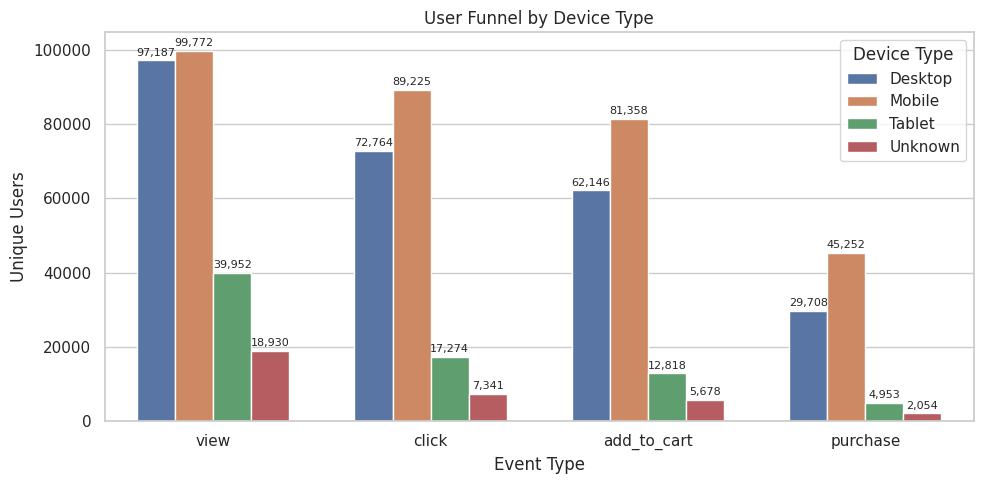

In [534]:
# Visualize funnel performance by device

event_order = [
    'view',
    'click',
    'add_to_cart',
    'purchase'
]

device_funnel['device_type'] = (
    device_funnel['device_type'].str.title()
)
device_order = [
    'Desktop',
    'Mobile',
    'Tablet',
    'Unknown'
]

plt.figure(figsize = (10, 5))

ax = sns.barplot(
    data = device_funnel,
    x = 'event_type',
    y = 'users',
    hue = 'device_type',
    order = event_order,
    hue_order = device_order,
    width = 0.7
)

plt.title('User Funnel by Device Type')
plt.xlabel('Event Type')
plt.ylabel('Unique Users')

# Add value labels
for container in ax.containers:
    ax.bar_label(
        container,
        fmt = '{:,.0f}',
        fontsize = 8,
        padding = 2
    )

plt.legend(title = 'Device Type')
plt.tight_layout()
plt.show()

### Funnel Performance by Traffic Source

Compare how different acquisition sources drive users through the funnel.

In [535]:
# Summarize funnel performance by traffic source

traffic_funnel = (
    events[events['event_type'] != 'bounce']
    .groupby(['traffic_source','event_type'])['customer_id']
    .nunique()
    .reset_index(name = 'users')
)

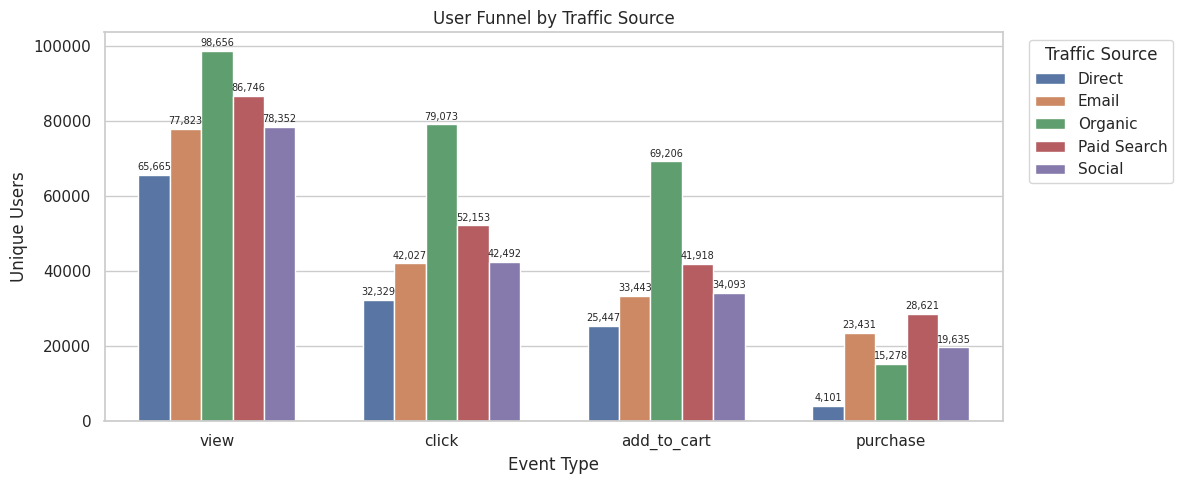

In [536]:
# Visualize funnel performance by traffic source

plt.figure(figsize = (12, 5))

ax = sns.barplot(
    data = traffic_funnel,
    x = 'event_type',
    y = 'users',
    hue = 'traffic_source',
    order = event_order,    
    width = 0.7
)

plt.title('User Funnel by Traffic Source')
plt.xlabel('Event Type')
plt.ylabel('Unique Users')

# Add value labels
for container in ax.containers:
    ax.bar_label(
        container,
        fmt = '{:,.0f}',
        fontsize = 7,
        padding = 2
    )

plt.legend(
    title = 'Traffic Source',
    bbox_to_anchor = (1.02, 1),
    loc = 'upper left'
)

plt.tight_layout()
plt.show()

### Funnel Performance by Campaign

Evaluate how different campaigns drive users through each funnel stage.

In [537]:
# Summarize campaign funnel performance

campaign_funnel = (
    events[events['event_type'] != 'bounce']
    .groupby(['campaign_id','event_type'])['customer_id']
    .nunique()
    .reset_index(name='users')
)

In [538]:
# Select the top-performing campaigns

top_campaigns = (
    campaign_funnel.groupby('campaign_id')['users']
    .sum()
    .sort_values(ascending = False)
    .head(10)
    .index
)

campaign_funnel_top = campaign_funnel[
    campaign_funnel['campaign_id'].isin(top_campaigns)
]

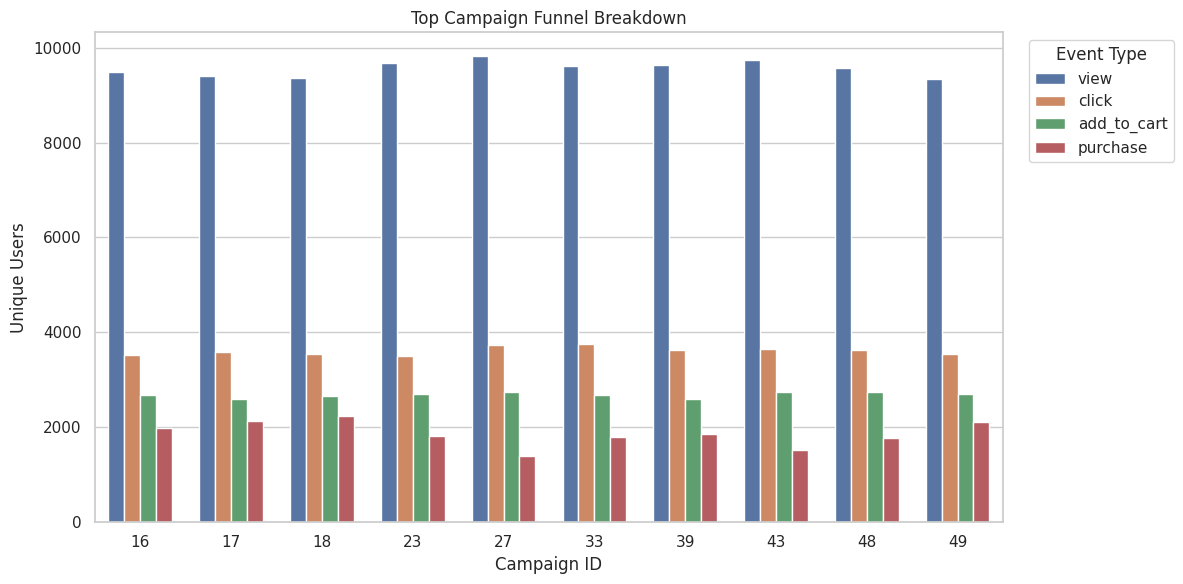

In [539]:
# Visualize campaign funnel performance

plt.figure(figsize = (12, 6))

ax = sns.barplot(
    data = campaign_funnel_top,
    x = 'campaign_id',
    y = 'users',
    hue = 'event_type',
    order = campaign_funnel_top['campaign_id'],
    hue_order = event_order,    
    width = 0.7
)

plt.title('Top Campaign Funnel Breakdown')
plt.xlabel('Campaign ID')
plt.ylabel('Unique Users')

plt.legend(
    title = 'Event Type',
    bbox_to_anchor = (1.02, 1),
    loc = 'upper left'
)

plt.tight_layout()
plt.show()

### Funnel Heatmap

Visualize funnel performance differences across acquisition sources.

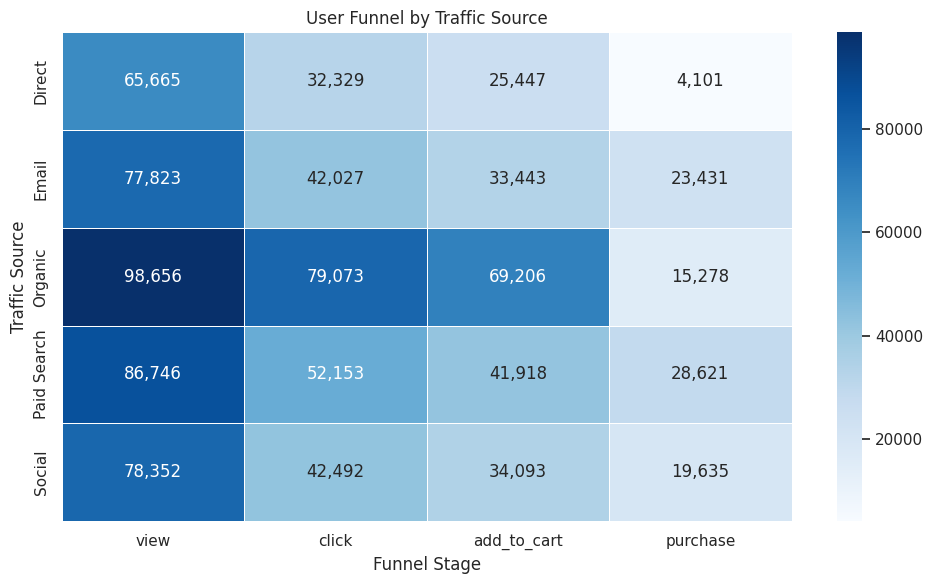

In [540]:
# Visualize funnel performance by traffic source

stage_order = [
    'view',
    'click',
    'add_to_cart',
    'purchase'
]

heatmap_data = (
    events[events['event_type'].isin(stage_order)]
    .groupby(['traffic_source', 'event_type'])['customer_id']
    .nunique()
    .unstack(fill_value = 0)
    .reindex(columns = stage_order)
)

plt.figure(figsize = (10, 6))

sns.heatmap(
    heatmap_data,
    annot = True,
    fmt = ',.0f',
    cmap = 'Blues',
    linewidths = 0.5
)

plt.title('User Funnel by Traffic Source')
plt.xlabel('Funnel Stage')
plt.ylabel('Traffic Source')

plt.tight_layout()
plt.show()

### Overall Conversion Rate

Calculate the percentage of users who completed a purchase after interacting with the platform.

In [541]:
# Calculate the overall purchase conversion rate

total_users = customers['customer_id'].nunique()

purchase_users = events[events['event_type'] == 'purchase']['customer_id'].nunique()

conversion_rate = purchase_users / total_users * 100

print(f"Conversion Rate: {conversion_rate:.2f}%")

Conversion Rate: 64.03%


### Key Findings

- In the overall user funnel, unique users decline from 99,997 views to 97,725 clicks, 94,228 add-to-cart users, and 64,035 purchase users.
- The largest step-level drop-off is add to cart → purchase: the step conversion rate is 67.96%, equivalent to a 32.04% drop-off among users counted at the add-to-cart stage.
- The displayed funnel excludes bounce events and counts unique users at each event type. Unless event order and session-level progression are enforced, this is a stage comparison rather than a strictly sequential funnel.
- Funnel purchase users (64,035) differ from the buyer count in the transaction/customer analysis (60.09% of 100,000, or about 60,090). Reconcile the event and transaction definitions before presenting these as one consistent conversion metric.
- The overall bounce calculation (85.05% of users had at least one bounce event) is not necessarily the conventional session-level bounce rate. Channel-level rates use users within each traffic source, and users can appear in multiple sources, so those rates are not directly additive.

## Module Summary

### Key findings:
- Acquisition-channel results show similar average purchase frequency across channels, with Organic leading customer volume and having the highest average CLV by a small margin in the displayed summary.
- Campaigns differ by total revenue, orders per session, and revenue per session; the highest-revenue campaign is not automatically the most efficient or profitable.
- The event-based funnel identifies the largest observed drop-off between add-to-cart and purchase (32.04% step drop-off).
- The event data shows 64,035 unique purchase users, while the customer/transaction analysis indicates a 60.09% buyer activation rate. These definitions or source populations need reconciliation before using them as a single KPI.
- Bounce-event rates should be described precisely and interpreted cautiously because the dataset counts events/users rather than explicitly defined sessions.
  
These findings suggest opportunities to improve checkout completion, evaluate channels using multiple quality metrics, and validate measurement definitions before making budget decisions.

# Overall Conclusions & Business Recommendations

## Key Findings
- Activation: The churn analysis classifies 60.09% of customers as buyers and 39.91% as never-purchased customers, making first-purchase activation a major opportunity.
- Customer value: RFM and CLV analyses identify a high-value segment with average adjusted CLV of `$329.78`, while the Low CLV segment has the highest average refund rate (10.59%).
- Retention: Under the 90-day inactivity definition, 85.90% of buyers are classified as churned. Cohort Month 1 repeat-purchase retention is generally only around 2%–3%.
- Acquisition: Organic has the largest customer count (18,210) and the highest average CLV (`$142.43`) in the acquisition summary, while channel churn rates are close together.
- Campaigns: Campaign 18 has the highest displayed revenue (`$187,497.20`), but revenue alone does not measure profitability or incremental impact.
- Funnel: The largest observed step drop-off is from add-to-cart to purchase (32.04%).
- Measurement caveat: The event funnel has 64,035 unique purchase users, whereas the churn/customer analysis has a 60.09% buyer activation rate (about 60,090 of 100,000 customers). Reconcile source populations and purchase definitions before reporting a single conversion KPI.
## Recommendations
1. Design first-purchase onboarding for the 39.91% never-purchased segment, and measure incremental buyer activation.
2. Protect Champions and Loyal Customers with relevant loyalty benefits and personalized communication.
3. Investigate the small refund-heavy cluster (1,713 customers; average refund rate 81.20%) and the Low CLV segment's elevated average refund rate.
4. Use the 90-day churn flag as a re-engagement trigger to test, not as a universally valid churn definition; validate it against actual repurchase cycles.
5. Evaluate acquisition channels jointly using volume, adjusted CLV, retention, refund rate, and acquisition cost where available.
6. Compare campaign revenue with efficiency, audience size, cost, and incremental lift before reallocating budget.
7. Investigate the add-to-cart → purchase drop-off through checkout diagnostics and cart-recovery tests.
## Limitations
- Historical adjusted revenue is a proxy for CLV and does not guarantee future revenue.
- The 90-day churn threshold is a business assumption and should be validated against the typical repurchase cycle.
- Logistic regression identifies associations rather than causal effects.
- Campaign cost and randomized incrementality are not represented in the displayed summary metrics, so profitability and causal campaign impact cannot be established.
- Funnel counts are based on unique users by event type; unless event order/session boundaries are enforced, they are not a strictly sequential funnel.
- Event-based purchase counts and transaction-based buyer counts currently differ and should be reconciled before finalizing conversion reporting.

In [542]:
# Export cleaned datasets to the working directory

customers.to_csv("/kaggle/working/customers_clean.csv", index = False)
transactions.to_csv("/kaggle/working/transactions_clean.csv", index = False)
events.to_csv("/kaggle/working/events_clean.csv", index = False)
products.to_csv("/kaggle/working/products_clean.csv", index = False)
campaigns.to_csv("/kaggle/working/campaigns_clean.csv", index = False)

print("✅ Cleaned data has been exported to /kaggle/working/")

✅ Cleaned data has been exported to /kaggle/working/
